## Challenge 01 (September-October 2026): Expected Credit Loss

This challenge wants to solve the next query:

"Good morning, 

We need to calculate the expected loss for the new portfolio we just acquired. These results will be used for provisions and must be validated by the regulator, so we need to be conservative to avoid potential penalties.

We need the data ready for the Committee meeting on October 25. We’ve attached the data we have on the portfolio.

Best regards, 

Big Boss"

The data used comes from [Credit Scoring | Lending Club Loan Data Cleared Kaggle page](https://www.kaggle.com/datasets/db0boy/lending-club-loan-data-cleared/data) and has two files: `X.csv` with the variables for modeling and `target.csv` with the binary target

In [1]:
# Import main libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# CONFIG
SEED = 42
TEST_SIZE = 0.2

# Set random seed for reproducibility
np.random.seed(SEED)

# Set styles
pd.set_option('display.float_format', lambda x: '%.3f' % x) 
sns.set_style("whitegrid")


In [2]:
# Transform csv to parquet 
# X = pd.read_csv("data/X.csv")
# X.to_parquet("data/X.parquet", index=False)

# y = pd.read_csv("data/target.csv")
# y.to_parquet("data/target.parquet", index=False)

In [3]:
# Read files
X = pd.read_parquet("data/X.parquet")
print(f"X shape: {X.shape}")
X.head()

X shape: (2139643, 45)


,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
0,2500,13.560,84.920,C1,Chef,10+ years,RENT,55000.000,Not Verified,debt_consolidation,...,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001
1,30000,18.940,777.230,D2,Postmaster,10+ years,MORTGAGE,90000.000,Source Verified,debt_consolidation,...,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987
2,5000,17.970,180.690,D1,Administrative,6 years,MORTGAGE,59280.000,Source Verified,debt_consolidation,...,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011
3,4000,18.940,146.510,D2,IT Supervisor,10+ years,MORTGAGE,92000.000,Source Verified,debt_consolidation,...,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006
4,30000,16.140,731.780,C4,Mechanic,10+ years,MORTGAGE,57250.000,Not Verified,debt_consolidation,...,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000


In [4]:
target = pd.read_parquet("data/target.parquet")
print(f"target shape: {target.shape}")
target.head()

target shape: (2139643, 1)


,y
0,0
1,0
2,0
3,0
4,0


In [5]:
target.value_counts(normalize=True)

y
0   0.869
1   0.131
Name: proportion, dtype: float64

It is, as expected, an unbalanced dataset as the number of defaults is much smaller than non-defaults

## Variable descriptions

The columns in `X.csv` fall into two groups, and this distinction is important:

- **Origination variables**: variables available at the time the loan is granted.
- **Performance variables**: variables observed after the loan is granted and constructed from the customer's payment history.

The second group is key: it allows us to reconstruct how much has actually been collected on each loan and how much remains outstanding. This lets us calculate observed LGD and EAD, and, in turn, the portfolio's realized loss.

**Data leakage:** **Performance variables (and Lending Club's `grade`) must not be used as inputs to our PD model**, because they were not available when the loan was granted. Using them would amount to cheating. They are, however, the basis for modeling LGD and EAD.

Descriptions published on the [Credit Scoring | Lending Club Loan Data Cleared Kaggle page](https://www.kaggle.com/datasets/db0boy/lending-club-loan-data-cleared/data) for the variables in X.csv.

| Variable | Description on Kaggle | Variable type | Origination subcategory |
|---|---|---|---|
| funded_amnt | The total amount committed to that loan at that point in time | Origination | A.1 Characteristics of Loan |
| interest_rate | Interest Rate on the loan | Origination | A.1 Characteristics of Loan |
| monthly_payment | The monthly payment owed by the borrower if the loan originates | Origination | A.1 Characteristics of Loan |
| grade | grade from C1 to A5, from worse to best respectively | Prohibited for PD | N/A |
| emp_title | The job title supplied by the Borrower when applying for the loan | Origination | A.2 Profile of Borrower |
| emp_length | Employment length in years | Origination | A.2 Profile of Borrower |
| home_ownership_status | The home ownership status provided by the borrower during registration | Origination | A.2 Profile of Borrower |
| annual_income | The self-reported annual income provided by the borrower during registration | Origination | A.2 Profile of Borrower |
| verification_status | Indicates if income was verified by LC, not verified, or if the income source was verified | Origination | A.2 Profile of Borrower |
| loan_purpose | A category provided by the borrower for the loan request | Origination | A.2 Profile of Borrower |
| addr_state | The state provided by the borrower in the loan application | Origination | A.2 Profile of Borrower |
| dept_paym_income_ratio | A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower’s self-reported monthly income | Origination | A.2 Profile of Borrower |
| num_30+_delinq_in_2yrs | The number of 30+ days past-due incidences of delinquency | Origination | A.3 Credit History at Origination |
| num_inq_in_6mths | The number of inquiries in past 6 months (excluding auto and mortgage inquiries) | Origination | A.3 Credit History at Origination |
| mths_since_last_delinq | The number of months since the borrower’s last delinquency | Origination | A.3 Credit History at Origination |
| num_open_credit_lines | The number of open credit lines in the borrower’s credit file | Origination | A.3 Credit History at Origination |
| num_derogatory_pub_rec | Number of derogatory public records | Origination | A.3 Credit History at Origination |
| total_credit_revolving_bal | Total credit revolving balance | Origination | A.3 Credit History at Origination |
| used_credit_share | Revolving line utilization rate, or the amount of credit the borrower is using relative to all assets | Origination | A.3 Credit History at Origination |
| tot_num_credit_lines | The total number of credit lines currently in the borrower’s credit file | Origination | A.3 Credit History at Origination |
| initial_list_status | The initial listing status of the loan | Origination | A.1 Characteristics of Loan |
| remaining_princ_for_tot_amnt_fund | Remaining outstanding principal for total amount funded | Performance | N/A |
| paym_rec_for_tot_amnt_fund | Payments received to date for total amount funded | Performance | N/A |
| princ_rec | Principal received to date | Performance | N/A |
| interest_rec | Interest received to date | Performance | N/A |
| late_fees_rec | Late fees received to date | Performance | N/A |
| num_open_trades_in_6mths | Number of open trades in last 6 months | Origination | A.3 Credit History at Origination |
| num_installment_acc_op_in_12mths | Number of installment accounts opened in past 12 months | Origination | A.3 Credit History at Origination |
| num_installment_acc_op_in_24mths | Number of installment accounts opened in past 24 months | Origination | A.3 Credit History at Origination |
| mths_since_last_installment_acc_op | Months since most recent installment accounts opened | Origination | A.3 Credit History at Origination |
| num_rev_trades_op_in_12mths | Number of revolving trades opened in past 12 months | Origination | A.3 Credit History at Origination |
| num_rev_trades_op_in_24mths | Number of revolving trades opened in past 24 months | Origination | A.3 Credit History at Origination |
| max_bal_owed | Maximum current balance owed on all revolving accounts | Origination | A.3 Credit History at Origination |
| bal_to_cred_lim | Balance to credit limit on all trades | Origination | A.3 Credit History at Origination |
| num_inq | Number of personal finance inquiries | Origination | A.3 Credit History at Origination |
| num_inq_in_12mths | Number of credit inquiries in past 12 months | Origination | A.3 Credit History at Origination |
| mths_since_recent_bankcard_delinq | Months since most recent bankcard delinquency | Origination | A.3 Credit History at Origination |
| mths_since_recent_revol_delinq | Months since most recent revolving delinquency | Origination | A.3 Credit History at Origination |
| disbursement_method | The method by which the borrower receives their loan | Origination | A.1 Characteristics of Loan |
| loan_term_months | Loan duration in months | Origination | A.1 Characteristics of Loan |
| issue_date_month | The month which the loan was funded | Origination | A.1 Characteristics of Loan |
| issue_date_year | The year which the loan was funded | Origination | A.1 Characteristics of Loan |
| region_code | Region code, ranging from "0" in the Northeast (e.g. Massachusetts, Connecticut) to "9" in the West (e.g. California, Alaska). | Origination | A.2 Profile of Borrower |
| earliest_cr_line_month | The month the borrower’s earliest reported credit line was opened | Origination | A.3 Credit History at Origination |
| earliest_cr_line_year | The year the borrower’s earliest reported credit line was opened | Origination | A.3 Credit History at Origination |

In [6]:
ORIGINATION_COLS = [
    # A.1 Characteristics of Loan
    'funded_amnt', 'interest_rate', 'monthly_payment', 'loan_term_months',
    'disbursement_method', 'initial_list_status', 'issue_date_month', 'issue_date_year',
    # A.2 Profile of Borrower
    'emp_title', 'emp_length', 'home_ownership_status', 'annual_income',
    'verification_status', 'loan_purpose', 'addr_state', 'region_code',
    'dept_paym_income_ratio',
    # A.3 Credit History at Origination
    'num_30+_delinq_in_2yrs', 'mths_since_last_delinq', 'num_derogatory_pub_rec',
    'num_inq', 'num_inq_in_6mths', 'num_inq_in_12mths',
    'num_open_credit_lines', 'tot_num_credit_lines',
    'total_credit_revolving_bal', 'used_credit_share', 'bal_to_cred_lim', 'max_bal_owed',
    'num_open_trades_in_6mths',
    'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths',
    'mths_since_last_installment_acc_op',
    'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths',
    'mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq',
    'earliest_cr_line_month', 'earliest_cr_line_year',
]

PERFORMANCE_COLS = ['princ_rec', 'interest_rec', 'late_fees_rec','paym_rec_for_tot_amnt_fund','remaining_princ_for_tot_amnt_fund']

PROHIBITED_PD = ['grade'] # classification variable, not allowed in PD model as it is a subjective rating

STRING_VAR = X.select_dtypes(include=['str']).columns.tolist()
NUMERIC_VAR = X.select_dtypes(include=['number']).columns.tolist()

print(STRING_VAR)
print(NUMERIC_VAR)
print(f"Number of string variables: {len(STRING_VAR)}")
print(f"Number of numeric variables: {len(NUMERIC_VAR)}")
print("All variables are categorized as string or numeric?", len(STRING_VAR) + len(NUMERIC_VAR) == X.shape[1])

['grade', 'emp_title', 'emp_length', 'home_ownership_status', 'verification_status', 'loan_purpose', 'addr_state', 'initial_list_status', 'disbursement_method', 'issue_date_month', 'earliest_cr_line_month']
['funded_amnt', 'interest_rate', 'monthly_payment', 'annual_income', 'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths', 'mths_since_last_delinq', 'num_open_credit_lines', 'num_derogatory_pub_rec', 'total_credit_revolving_bal', 'used_credit_share', 'tot_num_credit_lines', 'remaining_princ_for_tot_amnt_fund', 'paym_rec_for_tot_amnt_fund', 'princ_rec', 'interest_rec', 'late_fees_rec', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'mths_since_last_installment_acc_op', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'num_inq', 'num_inq_in_12mths', 'mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq', 'loan_term_months', 'issue_date_year', 'region_co

In [7]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=TEST_SIZE, random_state=SEED, stratify=target)
y_train, y_test = y_train.values.ravel(), y_test.values.ravel()

print(f"Distribution after splitting into train and test sets with {(1-TEST_SIZE)*100:.0f}/{TEST_SIZE*100:.0f} train/test:")
for name, y in zip(['Train', 'Test'], [y_train, y_test]):
    print(f"{name}: {len(y)} samples | default rate: {y.mean() * 100:.2f} %")

Distribution after splitting into train and test sets with 80/20 train/test:
Train: 1711714 samples | default rate: 13.07 %
Test: 427929 samples | default rate: 13.07 %


## General Study of Features

In [8]:
# Information of variables for modeling
print(X_train.dtypes.value_counts())
print()
X_train.info()

float64    22
int64      12
str        11
Name: count, dtype: int64

<class 'pandas.DataFrame'>
Index: 1711714 entries, 1483319 to 1393721
Data columns (total 45 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   funded_amnt                         int64  
 1   interest_rate                       float64
 2   monthly_payment                     float64
 3   grade                               str    
 4   emp_title                           str    
 5   emp_length                          str    
 6   home_ownership_status               str    
 7   annual_income                       float64
 8   verification_status                 str    
 9   loan_purpose                        str    
 10  addr_state                          str    
 11  dept_paym_income_ratio              float64
 12  num_30+_delinq_in_2yrs              int64  
 13  num_inq_in_6mths                    int64  
 14  mths_since_last_delinq              flo

### String Variables

In [9]:
# Checking the number of unique values in string variables
X_train[STRING_VAR].nunique().sort_values(ascending=False)

emp_title                 419267
addr_state                    51
grade                         35
loan_purpose                  14
issue_date_month              12
earliest_cr_line_month        12
emp_length                    11
home_ownership_status          4
verification_status            3
disbursement_method            2
initial_list_status            2
dtype: int64

This analysis shows that some of the string variables can be tuned into numeric variables: 
- Some of then represent months, which can be turned into their numerical representation
- Some of then are binary, which is easily coded keeping just one variable, whereas other have 3 or 4 possible values, which cane be handled using techniques as OHE


In [10]:
# Checking the number of unique values in numeric variables after removing spaces and converting to lower case
X_train["emp_title"] = X_train["emp_title"].str.lower().str.strip()
X_train["emp_title"].nunique()

338431

In [11]:
X_train['emp_title'].value_counts().head(10)

emp_title
teacher             34982
manager             34938
owner               25615
registered nurse    17684
supervisor          16843
driver              16825
sales               14490
rn                  13081
office manager      10553
project manager     10525
Name: count, dtype: int64

In [12]:
X_train['emp_title'].value_counts().tail(10)  

emp_title
warehouse/backup driver              1
west horizon adventures              1
exceptions processor                 1
senior certified credit counselor    1
me3                                  1
food retail                          1
bus dr                               1
boiler                               1
verizon federal, inc                 1
certified nurses asst                1
Name: count, dtype: int64

Although some values are representative, there are some that are just used one as some are very specific roles. Further study must assess if there are nulls and if it is possible to merge some titles that are written in different terms although they represent the same

In [13]:
X_train['addr_state'].unique()

<ArrowStringArray>
['NY', 'TN', 'TX', 'OR', 'GA', 'NJ', 'MD', 'PA', 'CA', 'LA', 'OH', 'ME', 'AZ',
 'MI', 'UT', 'SC', 'IL', 'CT', 'NC', 'FL', 'AL', 'VA', 'IN', 'NV', 'WA', 'MO',
 'CO', 'MA', 'MN', 'RI', 'HI', 'DE', 'KS', 'NH', 'NM', 'KY', 'MS', 'AR', 'WI',
 'OK', 'VT', 'WV', 'NE', 'WY', 'MT', 'DC', 'ND', 'AK', 'SD', 'ID', 'IA']
Length: 51, dtype: str

This variable represents the 51 states of USA so it can be coded to integer labels if the model can't handle string variables

In [14]:
X_train['loan_purpose'].unique()

<ArrowStringArray>
['debt_consolidation',        'credit_card',   'home_improvement',
              'other',              'house',             'moving',
            'medical',            'wedding',     'major_purchase',
     'small_business',                'car',           'vacation',
   'renewable_energy',        'educational']
Length: 14, dtype: str

This variable reprents a categorization into 14 possible purpose of the loan, including a category `other` which helps to not increasing the number of possible values

In [15]:
X_train['emp_length'].unique()

<ArrowStringArray>
[  '6 years',   '9 years', '10+ years',         nan,    '1 year',  '< 1 year',
   '4 years',   '7 years',   '5 years',   '8 years',   '2 years',   '3 years']
Length: 12, dtype: str

The possible values for this variable go from less than a year to 9 years plus 10 years or more and a NaN value that has to be studied as this variable represents the employment length in years, so it could be for instance that they do not have any job or they are retired. However, this variable is also easy to code into a numeric variable just using the number of years and using other numbers for some possible values

### Numeric Variables

In [16]:
def plot_hist_boxplots(X, y, var, axes, bins=10, sample_size=50_000, seed=SEED):
    """
    Function to plot histogram and boxplot for a given variable in a dataframe eliminating missing values.

    Parameters:
    X (pd.DataFrame): The input dataframe containing the variable.
    y (numpy.ndarray): The target variable for coloring the boxplot.
    var (str): The name of the variable to plot.
    axes (list): A list of matplotlib axes to plot the histogram and boxplot.
    bins (int): The number of bins for the histogram. Default is 10.
    sample_size (int): The number of samples to use for the boxplot. Default is 50,000.
    seed (int): The random seed for sampling. Default is SEED.

    Returns:
    None
    """
    # Use positional values so X and y remain aligned after filtering.
    plot_data = pd.DataFrame({
        var: X[var].to_numpy(),
        "target": np.asarray(y).ravel(),
    }).dropna(subset=[var, "target"])

    # Treat 0 and 1 as groups rather than numeric measurements.
    plot_data["target"] = plot_data["target"].replace({0: "Non-default", 1: "Default"})

    # Use a sample only for the boxplots.
    box_data = plot_data.sample(
        n=min(sample_size, len(plot_data)),
        random_state=seed
    )

    axes[0].hist(
        plot_data[var],
        bins=bins,
        color="skyblue",
        edgecolor="black"
    )
    axes[0].set_title(f"Histogram of {var}")
    axes[0].set_xlabel(var)
    axes[0].set_ylabel("Frequency")

    sns.boxplot(
        data=box_data,
        x=var,
        y="target",
        orient="h",
        showfliers=False,
        ax=axes[1]
    )
    axes[1].set_title(f"Boxplot of {var} by target")
    axes[1].set_xlabel(var)
    axes[1].set_ylabel("Target")

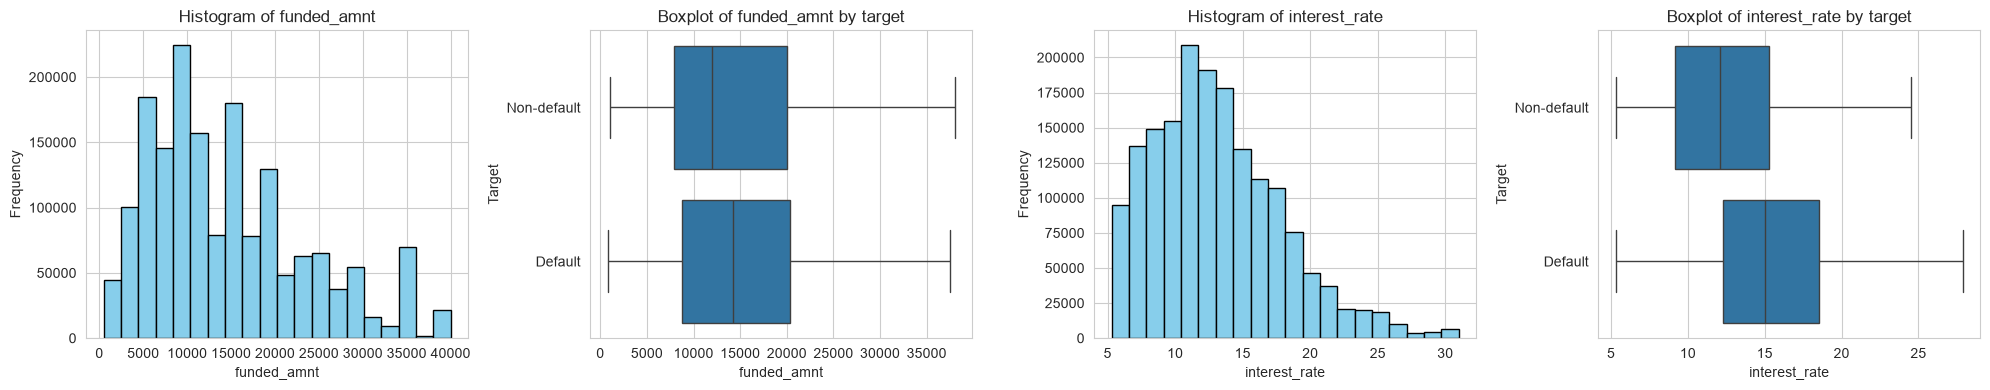

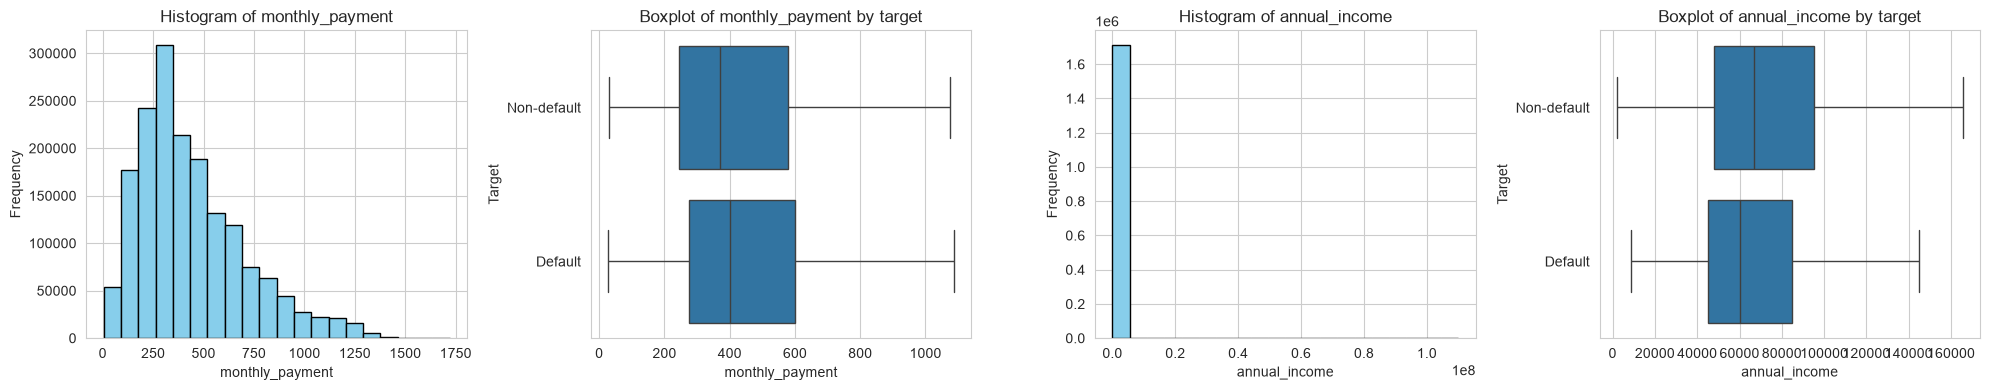

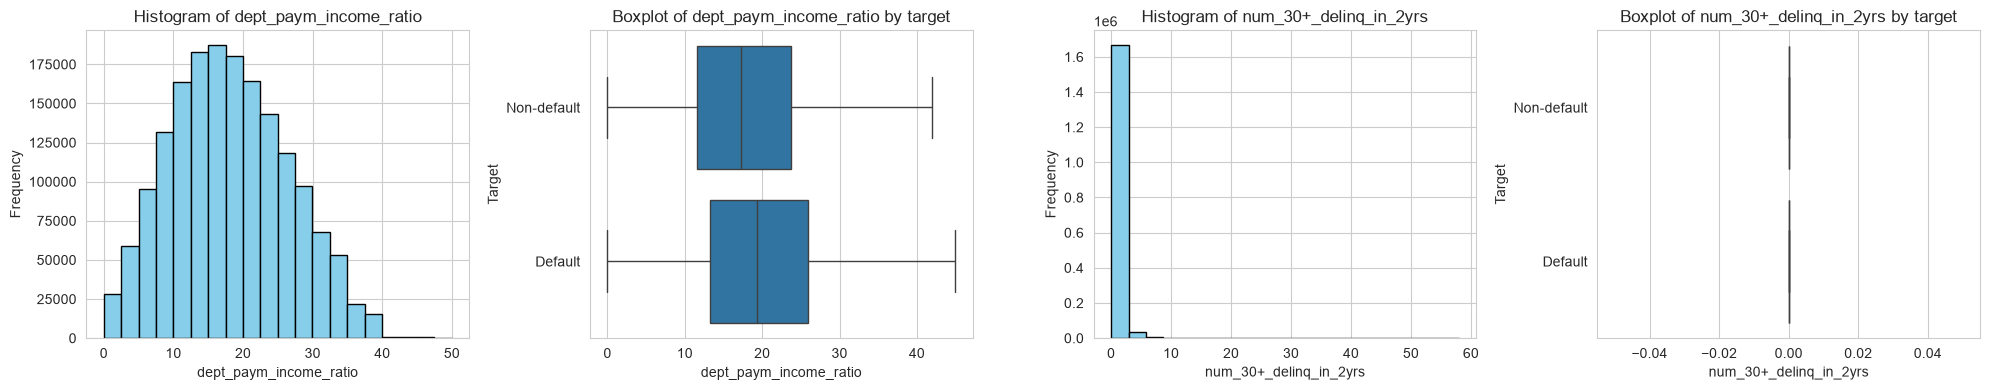

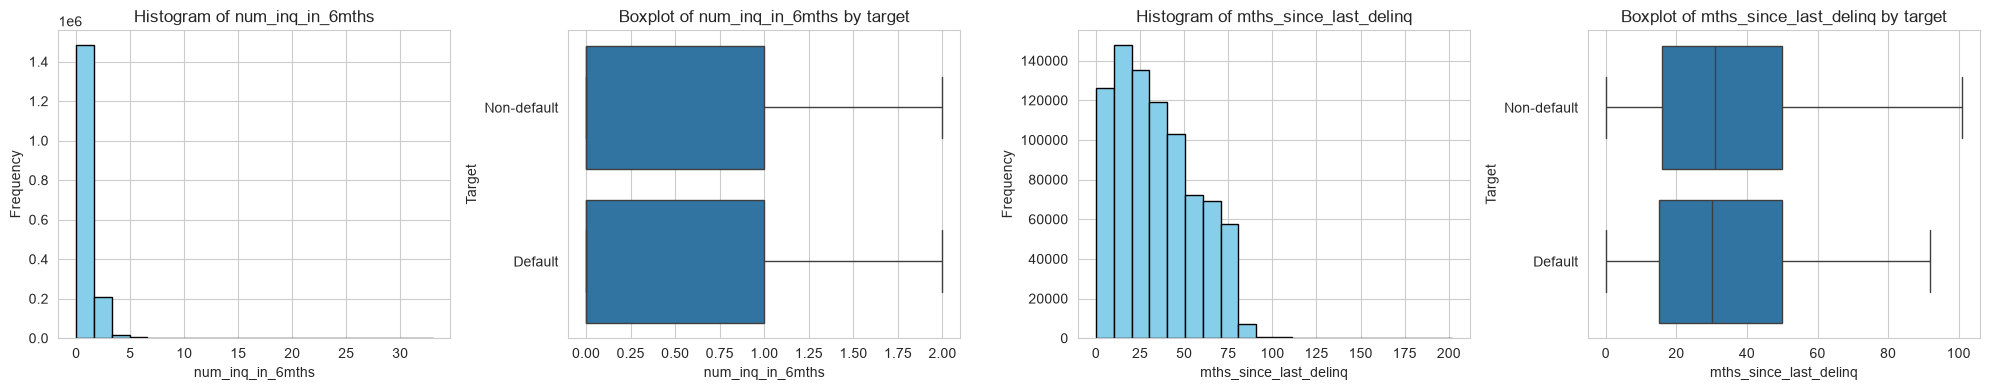

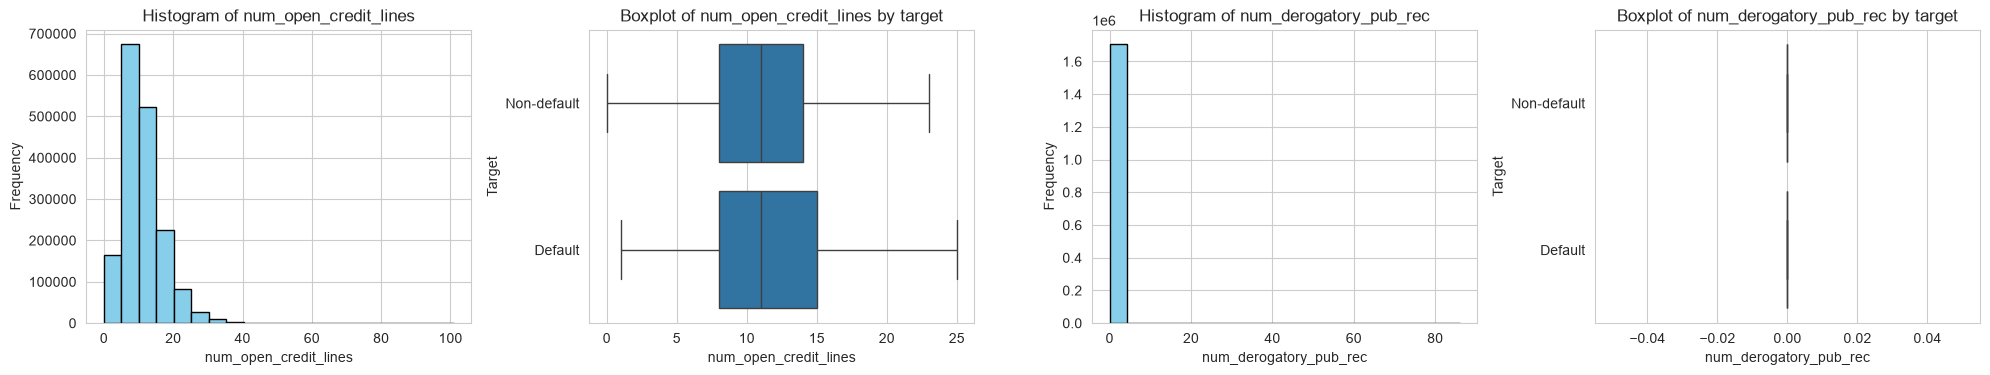

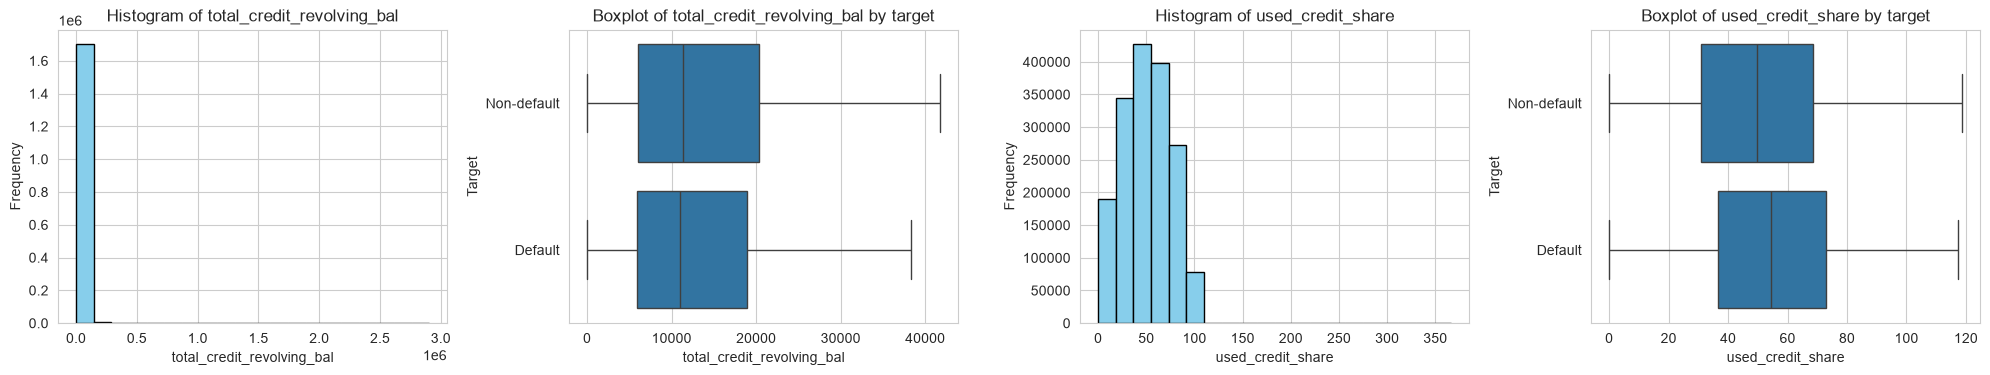

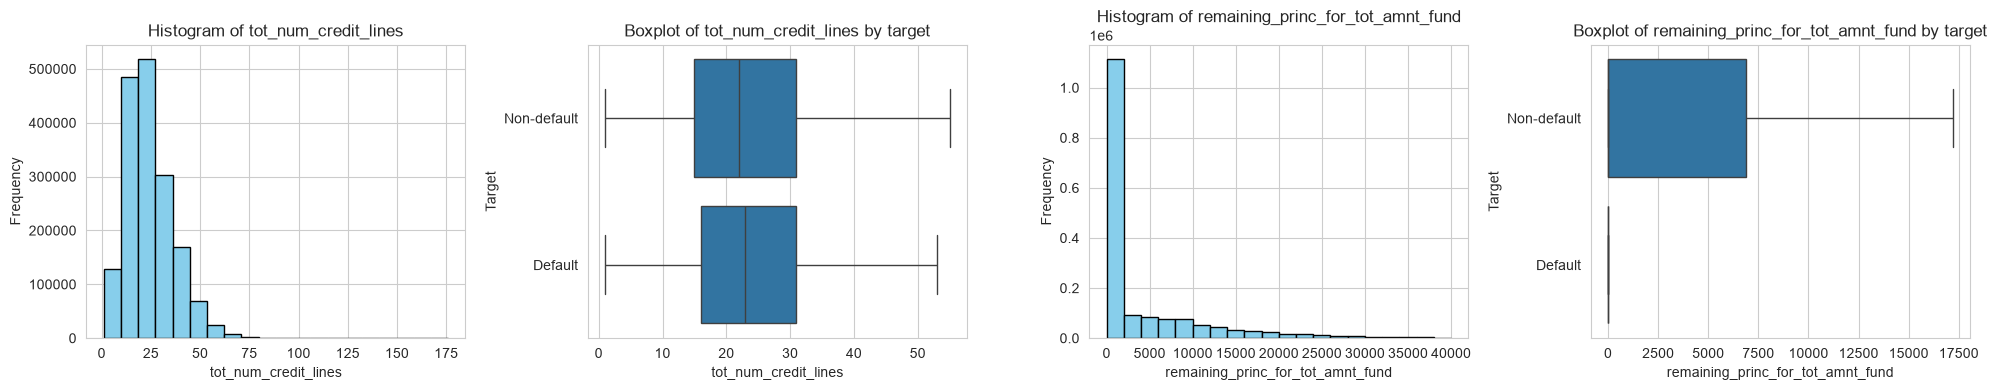

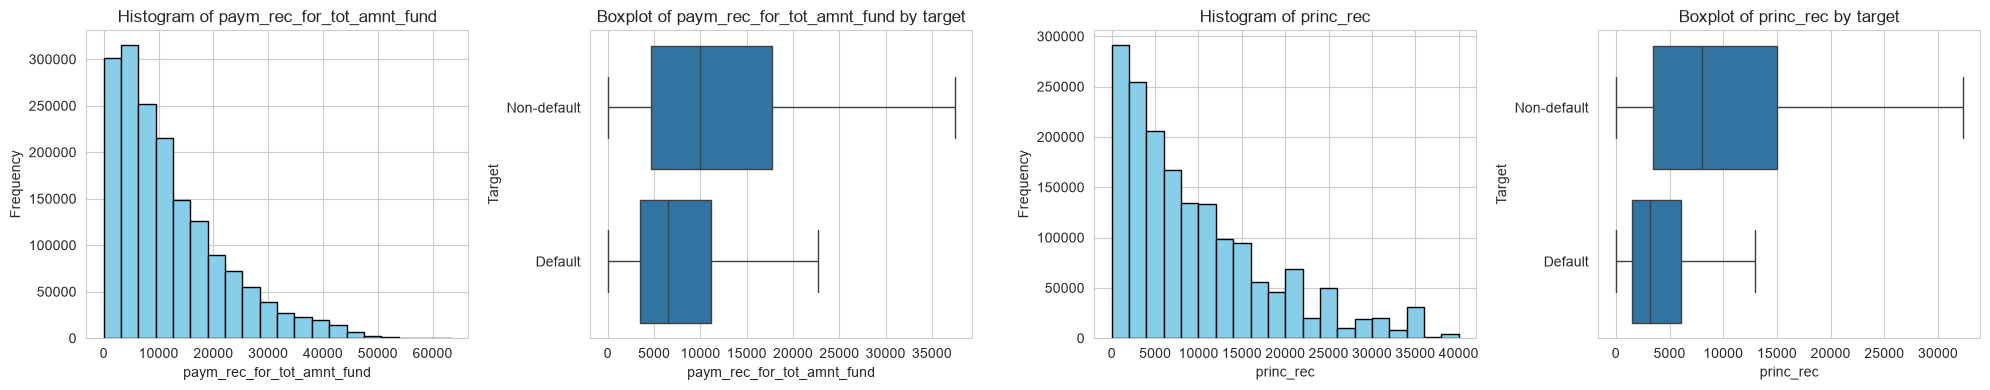

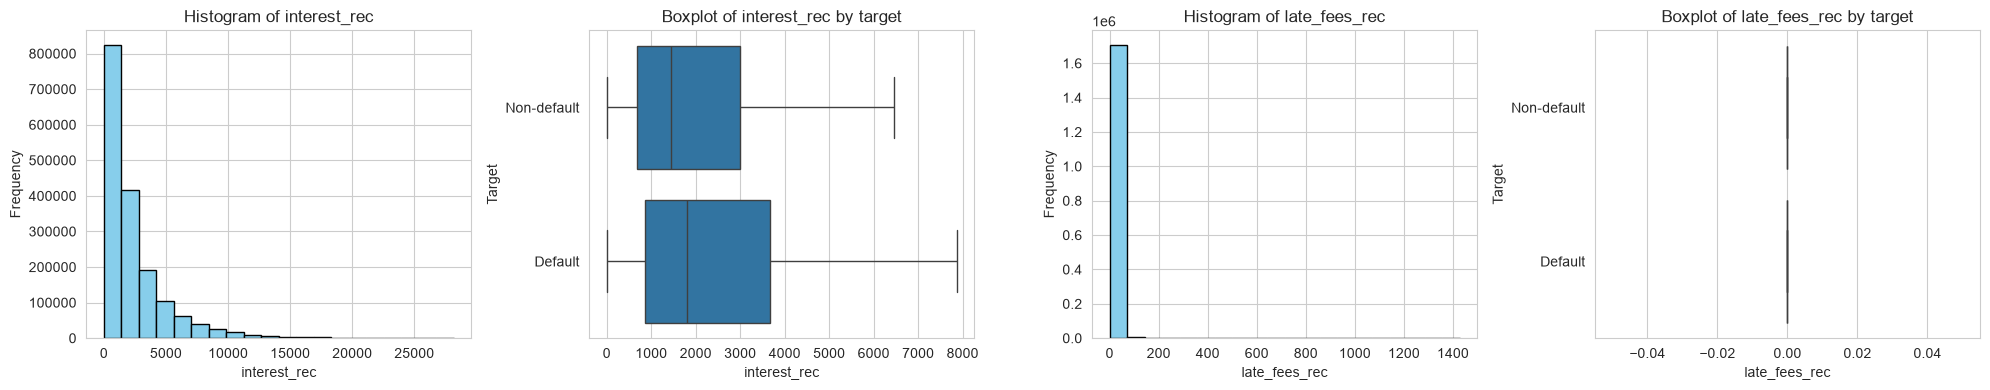

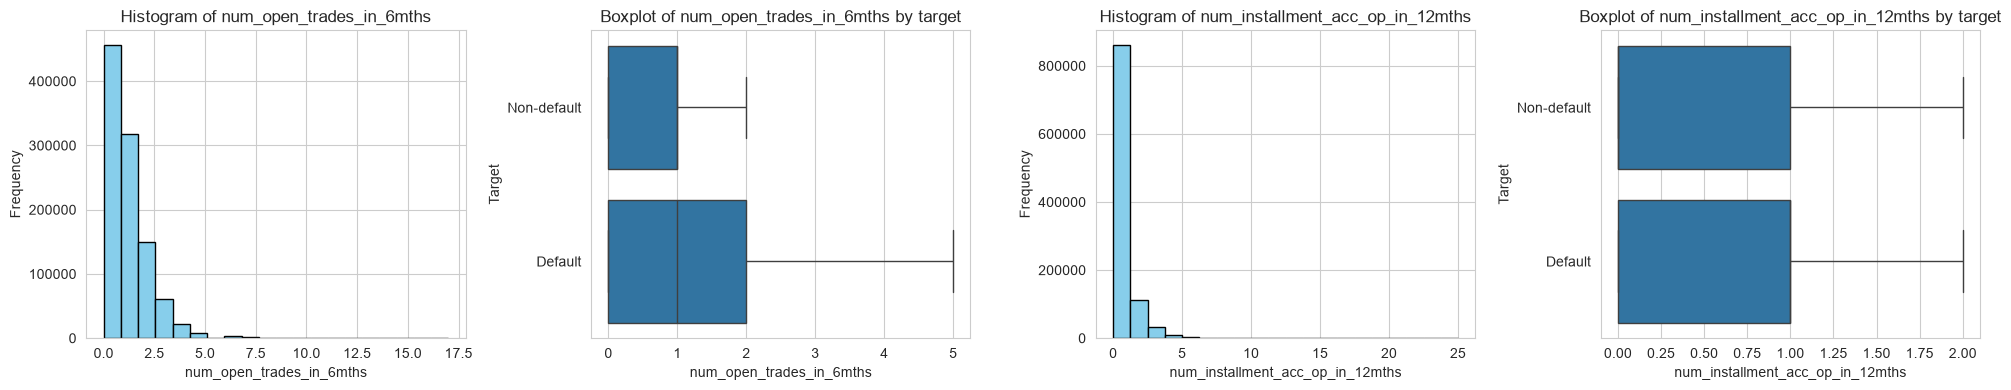

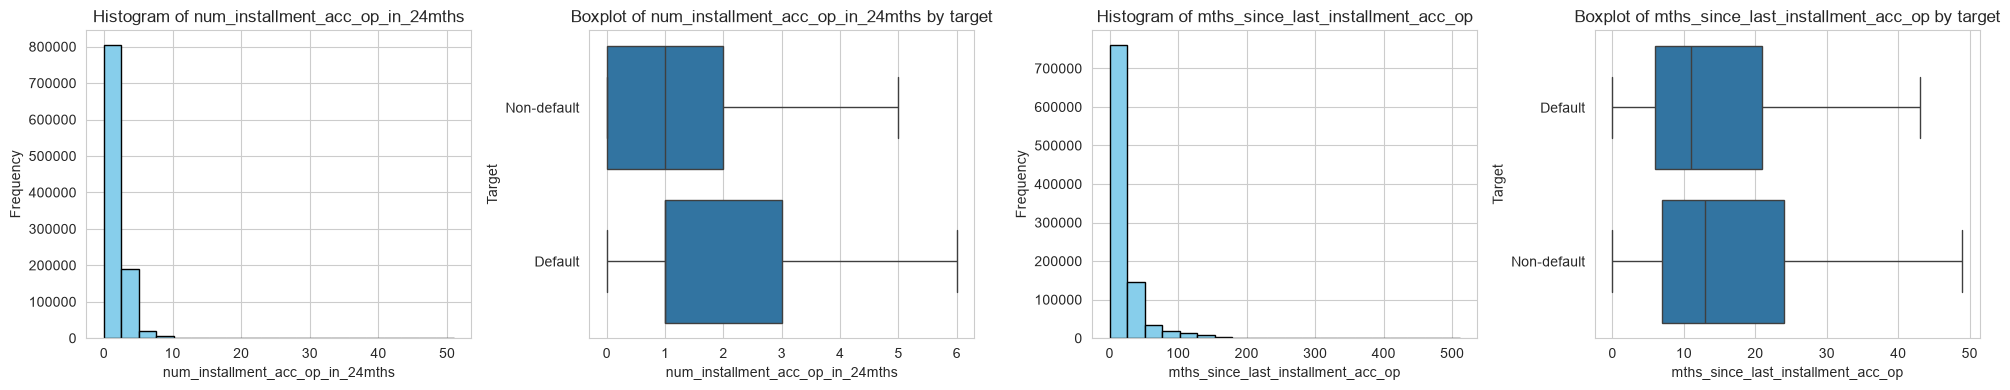

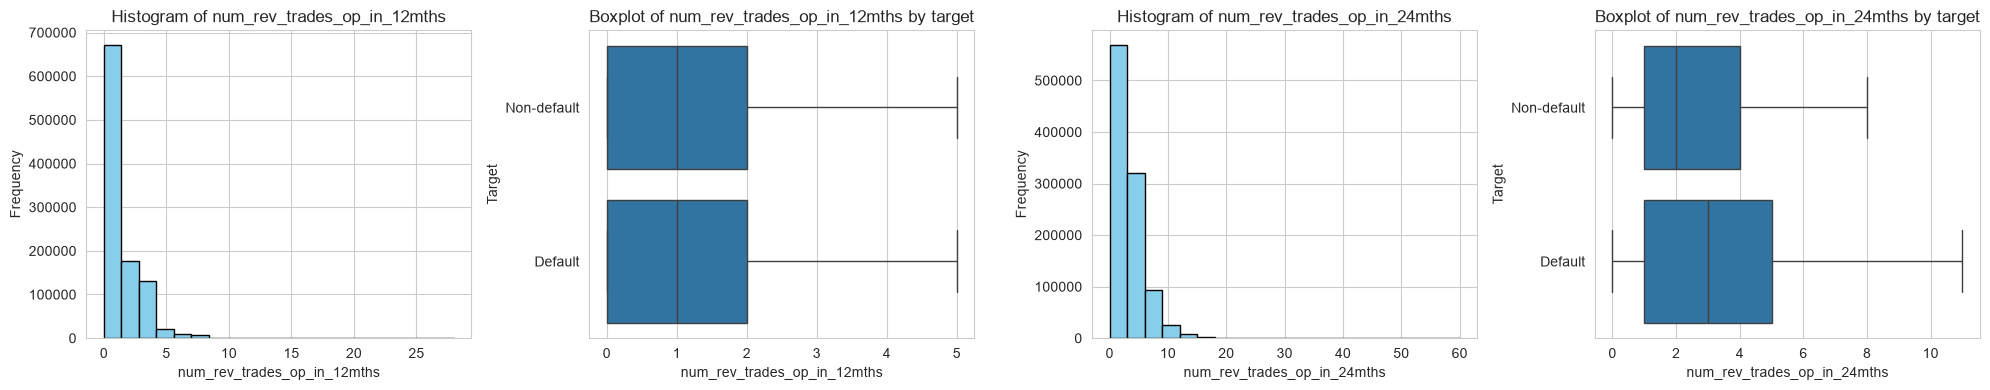

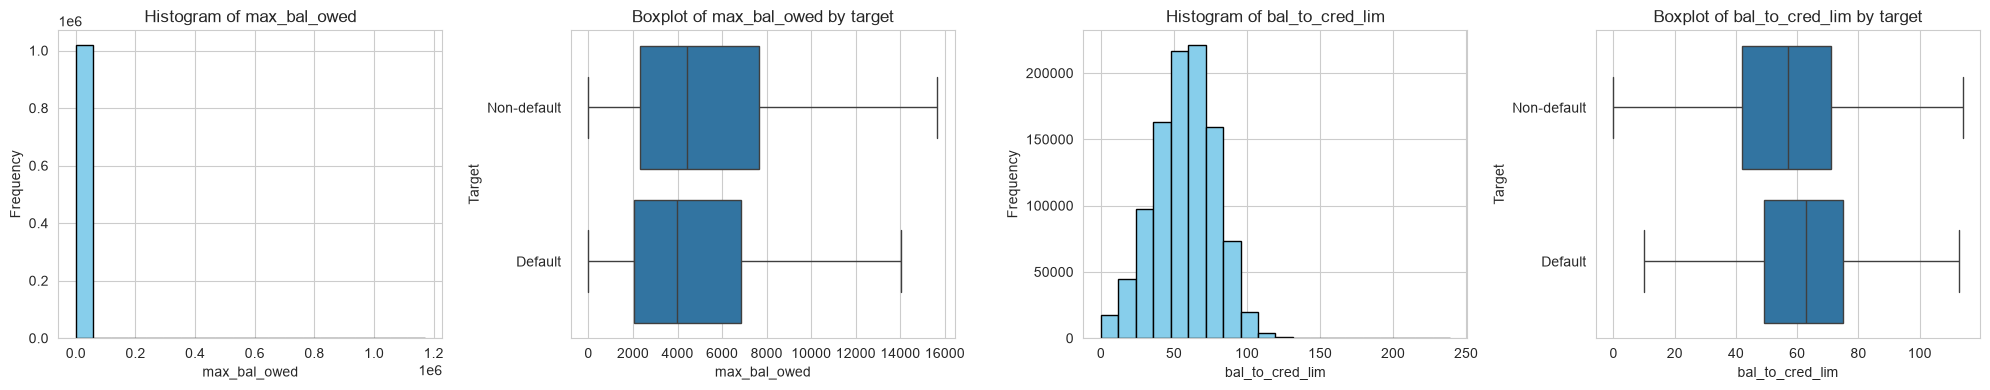

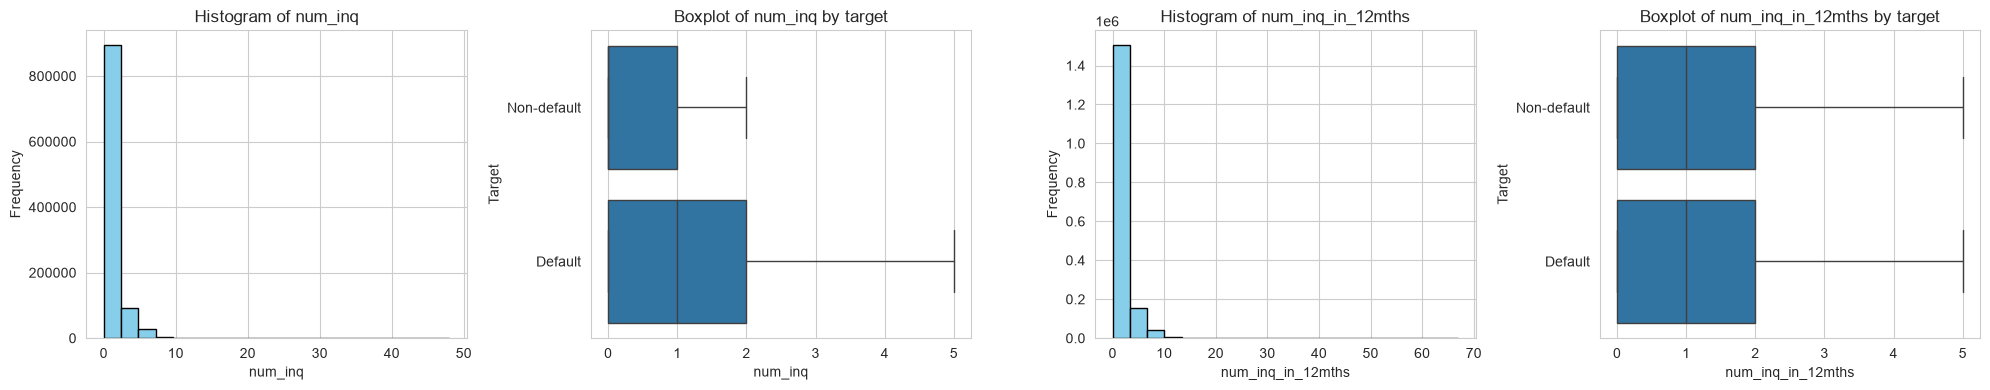

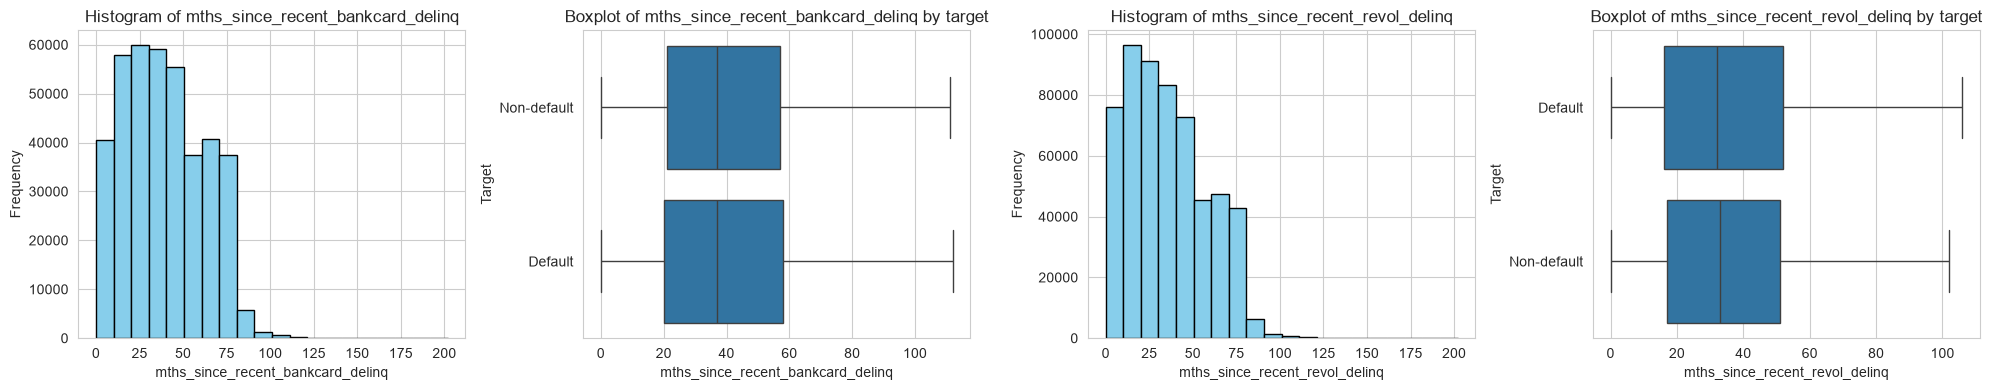

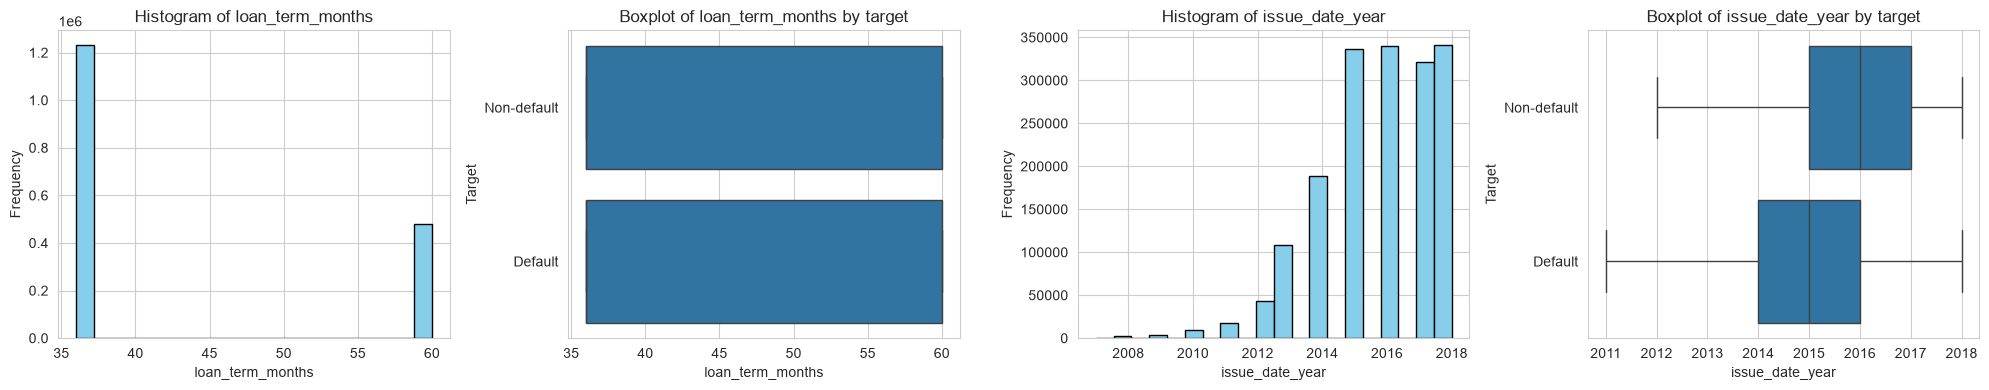

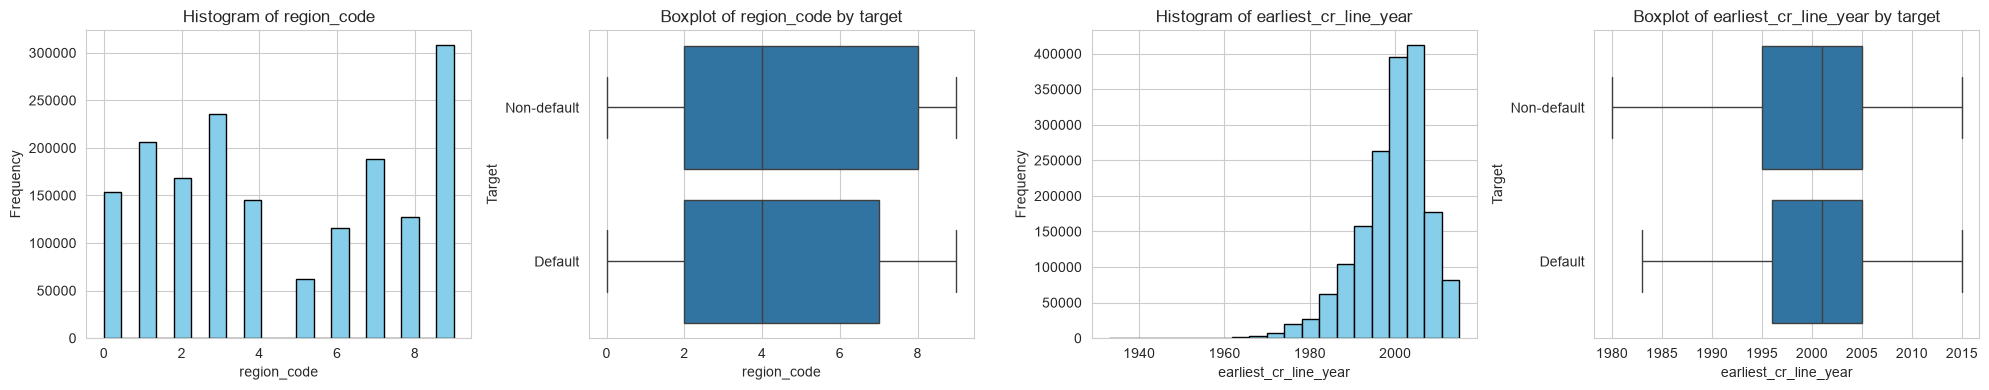

In [17]:
# Process two variables per figure.
for i in range(0, len(NUMERIC_VAR), 2):
    variables = NUMERIC_VAR[i:i + 2]

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    for j, var in enumerate(variables):
        plot_hist_boxplots(
            X_train,
            y_train,
            var,
            axes=axes[j * 2:j * 2 + 2],
            bins=20
        )

    # Hide unused axes if the last row contains only one variable.
    if len(variables) == 1:
        axes[2].set_visible(False)
        axes[3].set_visible(False)

    plt.tight_layout()
    plt.show()

### Key takeaways from histograms and boxplots (SEED = 42)

- **Several monetary variables have long right tails.** This is especially visible for `annual_income`, `total_credit_revolving_bal` and `max_bal_owed`, where large values compress most observations into the first histogram bin. Percentiles and log-scaled plots can help examine their distributions. Large values should be investigated before being treated as errors or removed.

- **Many count variables are concentrated at zero or low values.** Examples include `num_30+_delinq_in_2yrs`, `num_derogatory_pub_rec` and recent credit inquiry and account-opening counts. For the first two variables, the boxplots collapse to a line at zero because the quartiles coincide. This does not mean all values are zero: positive values are present but are hidden in the boxplots because outlier points are not displayed. Frequency tables or bar plots may describe these variables more clearly.

- **Interest rates differ between default groups.** The median `interest_rate` is higher among loans that defaulted, although the distributions overlap. The default group also shows higher medians for `dept_paym_income_ratio`, `used_credit_share` and `bal_to_cred_lim`. These are descriptive associations; the plots alone do not establish causality or show how well each variable predicts default.

- **Some recent credit activity variables also differ by group.** Among observations with available data, defaulted loans show higher typical values for `num_open_trades_in_6mths`, `num_installment_acc_op_in_24mths` and `num_inq`. These variables have substantial missingness, so the comparison describes only the records shown and should be interpreted alongside the missing-value analysis.

- **Discrete and categorical variables need suitable plots.** `loan_term_months` takes two values, 36 and 60 months; a frequency table and default rate by term would be more informative than a boxplot. `funded_amnt` has visible concentrations at common loan amounts. `region_code` represents geographic categories, so differences between its numeric codes and its boxplot should not be interpreted as meaningful distances.

- **Loan issue years are concentrated in 2014–2018.** The boxplots also show an earlier median issue year for defaulted loans. This pattern may be affected by differences in how long each loan has been observed: more recent loans have had less time to default. A time-based evaluation could help assess performance on later vintages, while accounting for loan maturity.

- **Performance variables show differences between the groups, but are measured after origination.** In the plots, defaulted loans generally have lower `princ_rec` and `paym_rec_for_tot_amnt_fund`. The `remaining_princ_for_tot_amnt_fund` boxplot also differs markedly, although its interpretation requires checking how outstanding balances are recorded after default. These variables are useful for reconstructing observed losses, but they are not available as predictors when estimating loss at origination.

The boxplots are based on a random sample and omit missing values and displayed outlier points. Their medians and quartiles are therefore approximate, and comparisons for variables with missing data apply only to observations with recorded values.

In [18]:
X_train[NUMERIC_VAR].describe().T

,count,mean,std,min,25%,50%,75%,max
funded_amnt,1711714.000,14783.143,9031.905,500.000,8000.000,12250.000,20000.000,40000.000
interest_rate,1711714.000,13.059,4.795,5.310,9.490,12.620,15.880,30.990
monthly_payment,1711714.000,439.257,263.274,4.930,249.190,373.220,581.580,1719.830
annual_income,1711714.000,78970.023,122054.060,1900.000,47303.250,65134.500,95000.000,110000000.000
dept_paym_income_ratio,1711714.000,18.087,8.421,0.000,11.770,17.590,24.030,49.960
num_30+_delinq_in_2yrs,1711714.000,0.310,0.873,0.000,0.000,0.000,0.000,58.000
num_inq_in_6mths,1711714.000,0.587,0.895,0.000,0.000,0.000,1.000,33.000
mths_since_last_delinq,838783.000,34.511,21.905,0.000,16.000,31.000,50.000,202.000
num_open_credit_lines,1711714.000,11.639,5.642,0.000,8.000,11.000,14.000,101.000
num_derogatory_pub_rec,1711714.000,0.200,0.577,0.000,0.000,0.000,0.000,86.000


### Key takeaways from describe (SEED = 42)

- **Several monetary variables have long upper tails.** Mean `annual_income` is $78,970, compared with a median of $65,135 and a maximum of $110 million. Similarly, `total_credit_revolving_bal` has a median of $11,321 and a maximum of approximately $2.9 million. These values warrant further inspection, but the summary alone does not establish whether they are errors.

- **Several risk-event counts are concentrated at zero.** The 75th percentile of both `num_30+_delinq_in_2yrs` and `num_derogatory_pub_rec` is zero, while their maxima are 58 and 86, respectively. The median of `num_inq_in_6mths` is also zero. Frequency tables can help describe the less common positive values.

- **Missingness varies substantially across variables.** Of the 1,711,714 training records, `mths_since_last_delinq` has 838,783 non-missing values and `mths_since_recent_bankcard_delinq` has 396,948. Seven recent credit-activity variables each have 1,019,198 non-missing values. Their matching counts suggest a common missingness pattern, but the count alone does not confirm that the same rows are missing. The meaning of these gaps should be investigated before choosing an imputation method.

- **Some ratios have unusually high values.** `used_credit_share` reaches 366.6 and `bal_to_cred_lim` reaches 239. Their definitions and these observations should be checked before deciding whether the values are plausible.

- **Loan terms and issue years are concentrated in specific groups.** The median `loan_term_months` is 36 and its 75th percentile is 60; the preceding histogram shows that 36 and 60 are the two observed terms. For `issue_date_year`, the median is 2016 and the middle 50% of loans were issued between 2015 and 2017. Differences in the observation period across years should be considered when comparing defaults.

- **Performance variables describe outcomes after origination.** For example, the median `princ_rec` is $7,000 and the median `remaining_princ_for_tot_amnt_fund` is zero. These summaries can help understand repayment and reconstruct observed loss, but the variables are unavailable as inputs when making predictions at origination.

## Analysis of Missing Values

### Numeric Features

In [19]:
# Numeric variables with missing values
missing_counts = X_train[NUMERIC_VAR].isna().sum()
missing_num_dataframe = pd.DataFrame({
    "variable": missing_counts.index,
    "missing_count": missing_counts.values,
    "missing_percentage": (missing_counts / len(X_train) * 100).values,
})

missing_num_dataframe = (
    missing_num_dataframe[missing_num_dataframe["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
    .reset_index(drop=True)
)

missing_num_dataframe


,variable,missing_count,missing_percentage
0,mths_since_recent_bankcard_delinq,1314766,76.810
1,mths_since_recent_revol_delinq,1147320,67.028
2,mths_since_last_delinq,872931,50.997
3,mths_since_last_installment_acc_op,724086,42.302
4,bal_to_cred_lim,692609,40.463
5,num_installment_acc_op_in_24mths,692516,40.457
6,num_open_trades_in_6mths,692516,40.457
7,num_installment_acc_op_in_12mths,692516,40.457
8,max_bal_owed,692516,40.457
9,num_rev_trades_op_in_24mths,692516,40.457


All numeric variables with missing values represent information where a missing value could represent that the user does not have any event of what the variable is measuring. For example, the first three variables with more missing values evaluate values related to deliquency, so these could be missing values as the user might not have any deliquency. However, deeper analysis is needed for this variables.

In addition, no performance feature has missing values.

In [20]:
# Define the block of columns with same amount of missing values to check if they are missing together or not
block = [
    "num_inq",
    "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_12mths",
    "num_rev_trades_op_in_24mths",
    "max_bal_owed",
]

missing_block = X_train[block].isna()
(missing_block.nunique(axis=1) == 1).mean()

np.float64(1.0)

In [21]:
# Number of missing values in the block of columns by year
X_train.groupby('issue_date_year')['num_inq'].agg(
    missing_count = lambda s: s.isna().sum(),
    record_count = "count",
    missing_percentage = lambda s: round(s.isna().sum() / len(s) * 100, 2)
)

,missing_count,record_count,missing_percentage
issue_date_year,,,
2007,441,0,100.000
2008,1949,0,100.000
2009,4231,0,100.000
2010,9990,0,100.000
2011,17417,0,100.000
2012,42715,0,100.000
2013,107993,0,100.000
2014,188520,0,100.000
2015,319210,16913,94.970


In [22]:
print("Check if 0 or 0.0 is present in the value counts of the block of columns:")
for c in block:
  print(c,":",(0 or 0.0) in X_train[c].value_counts().index)

Check if 0 or 0.0 is present in the value counts of the block of columns:
num_inq : True
num_open_trades_in_6mths : True
num_installment_acc_op_in_12mths : True
num_installment_acc_op_in_24mths : True
num_rev_trades_op_in_12mths : True
num_rev_trades_op_in_24mths : True
max_bal_owed : True


As the result of this analysis is 1, all the variables with 40.457 % of missing values are missing for the same users. Moreover, all the missing values finish on 2015 having 8 years with all missing values

Therefore, as these features measure the number of events of "X", the wisest is to interpret their missings as not recorded samples due to its distribution (until 2015 they are all missings) and the fact that there are samples with a 0 value. 

In [23]:
# Check missing values of bal_to_cred_lim   
mask = X_train['max_bal_owed'].isna()                  
X_train.loc[mask, 'bal_to_cred_lim'].isna().mean()

np.float64(1.0)

In [24]:
mask = ~X_train['max_bal_owed'].isna() & X_train['bal_to_cred_lim'].isna()
X_train[mask]['max_bal_owed'].describe()   

count   93.000
mean     0.000
std      0.000
min      0.000
25%      0.000
50%      0.000
75%      0.000
max      0.000
Name: max_bal_owed, dtype: float64

`bal_to_cred_lim` is missing always than the rest of the previously assessed ones are missing and the value of `max_bal_owed` is 0 always than the latter is not missing and the former is. Therefore, it can be assumed that a missing value of `bal_to_cred_lim` is for users with no credit. 

In [25]:
# Check missing values of mths_since_last_installment_acc_op
mask = X_train['num_installment_acc_op_in_24mths'].isna()                  
X_train.loc[mask, 'mths_since_last_installment_acc_op'].isna().mean()

np.float64(1.0)

In [26]:
mask = ~X_train['num_installment_acc_op_in_24mths'].isna() & X_train['mths_since_last_installment_acc_op'].isna()
X_train[mask][["num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths"]].describe().T    

,count,mean,std,min,25%,50%,75%,max
num_installment_acc_op_in_12mths,31570.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
num_installment_acc_op_in_24mths,31570.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [27]:
col = "mths_since_last_installment_acc_op"

summary = (
    X_train.loc[mask]
     .groupby("issue_date_year")[col]
     .agg(
         records="size",
         available_values="count",
         missing_values=lambda s: s.isna().sum(),
         missing_percentage=lambda s: s.isna().mean() * 100
     )
)

print(summary)

                 records  available_values  missing_values  missing_percentage
issue_date_year                                                               
2015                 429                 0             429             100.000
2016                9155                 0            9155             100.000
2017                9353                 0            9353             100.000
2018               12633                 0           12633             100.000


As it occured with `bal_to_cred_lim`, `mths_since_last_installment_acc_op` is missing always than the rest of the assessed ones are missing and always than the number of installment accounts opened in the last 2 years is 0. Therefore a missing value can be treated, as assumption, as users with no installment accounts. However, it is compared with two vairables that measure just 2 recent years, so for the previous ones, it cannot be stated that users did not have installment accounts, but it will be an assumption.

Let’s see how often the delinquency variables are missing when `num_inq` is also missing. If these gaps tend to appear together, they may be related to the same availability or reporting pattern.


In [28]:
# Check missing values of delinquency-history fields with the recorded delinquency count
delinq_month_vars = [
    "mths_since_last_delinq",
    "mths_since_recent_bankcard_delinq",
    "mths_since_recent_revol_delinq",
]

mask = X_train['num_inq'].isna()                  
X_train.loc[mask, delinq_month_vars].isna().mean()


mths_since_last_delinq              0.513
mths_since_recent_bankcard_delinq   0.767
mths_since_recent_revol_delinq      0.673
dtype: float64

In this case, there isn't a clear pattern of relation between missing values between delinquency variables and the rest missing variables, as the former have a longer set of missing values and the rows do not match as much as they did for the previous block

Let’s compare the number of recent delinquencies for loans with and without a value in each of these variables. This can help us see whether a missing value is always consistent with having no recorded delinquency.


In [29]:
# Compare missing delinquency-history fields with the recorded delinquency count
count_col = "num_30+_delinq_in_2yrs"

results = []

for variable in delinq_month_vars:
    comparison = (
        X_train.assign(missing_field=X_train[variable].isna())
         .groupby("missing_field")[count_col]
         .agg(
             non_missing_count="count",
             median="median",
             zero_percentage=lambda s: s.dropna().eq(0).mean() * 100,
             positive_percentage=lambda s: s.dropna().gt(0).mean() * 100
         )
         .reset_index()
    )
    comparison.insert(0, "variable", variable)
    results.append(comparison)

print("Comparison of missing delinquency-history fields with the recorded delinquency count:")
delinq_comparison = pd.concat(results, ignore_index=True)
delinq_comparison

Comparison of missing delinquency-history fields with the recorded delinquency count:


,variable,missing_field,non_missing_count,median,zero_percentage,positive_percentage
0,mths_since_last_delinq,False,838783,0.000,62.082,37.918
1,mths_since_last_delinq,True,872931,0.000,99.566,0.434
2,mths_since_recent_bankcard_delinq,False,396948,0.000,56.967,43.033
3,mths_since_recent_bankcard_delinq,True,1314766,0.000,88.513,11.487
4,mths_since_recent_revol_delinq,False,564394,0.000,57.100,42.900
5,mths_since_recent_revol_delinq,True,1147320,0.000,93.052,6.948


Let’s look at missing values by issue year. If some years have far more gaps than others, the differences may reflect changes in data availability rather than borrower behaviour.


In [30]:
# Check whether delinquency-field missingness varies by loan issue year
missing_by_year = (
    X_train.groupby("issue_date_year")[delinq_month_vars]
     .agg(lambda column: column.isna().mean() * 100)
     .round(2)
)
missing_by_year['number_of_loans'] = X_train.groupby('issue_date_year').size()
print("Percentage of missing values in delinquency fields by loan issue year:")
missing_by_year


Percentage of missing values in delinquency fields by loan issue year:


,mths_since_last_delinq,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,number_of_loans
issue_date_year,,,,
2007,0.910,100.000,100.000,441
2008,38.170,100.000,100.000,1949
2009,66.840,100.000,100.000,4231
2010,64.300,100.000,100.000,9990
2011,66.190,100.000,100.000,17417
2012,58.790,87.330,73.790,42715
2013,56.520,77.750,69.990,107993
2014,49.180,73.540,64.000,188520
2015,48.480,74.260,64.030,336123


Compare the default rate and number of loans with missing and observed values for each delinquency variable. Missing values remain a separate group because they may reflect unrecorded information, no applicable product or no reported delinquency.


In [31]:
# Compare missing and observed values, including group sizes.
target_train = pd.Series(np.asarray(y_train).ravel(), index=X_train.index, name="target")
rows = []

for col in delinq_month_vars:
    for label, mask in [("Missing", X_train[col].isna()), ("Observed", X_train[col].notna())]:
        n = int(mask.sum())
        rows.append({"variable": col, "group": label, "n": n,
                     "share_pct": 100 * n / len(X_train),
                     "default_pct": 100 * target_train.loc[mask].mean()})
        
missing_default = pd.DataFrame(rows)
print(missing_default.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

                         variable    group       n  share_pct  default_pct
           mths_since_last_delinq  Missing  872931      51.00        12.42
           mths_since_last_delinq Observed  838783      49.00        13.76
mths_since_recent_bankcard_delinq  Missing 1314766      76.81        12.75
mths_since_recent_bankcard_delinq Observed  396948      23.19        14.13
   mths_since_recent_revol_delinq  Missing 1147320      67.03        12.72
   mths_since_recent_revol_delinq Observed  564394      32.97        13.79


Default rates are `mths_since_last_delinq`: 12.42% versus 13.76% (missing versus observed; 51.00% missing); `mths_since_recent_revol_delinq`: 12.72% versus 13.79% (missing versus observed; 67.03% missing); `mths_since_recent_bankcard_delinq`: 12.75% versus 14.13% (missing versus observed; 76.81% missing). These are descriptive differences, not evidence that missing values mean no delinquency. Issue-year availability and borrower characteristics may also affect the comparison.

We can estimate the length of each borrower’s credit history from their first reported credit line and the loan issue date. Checking this calculation first gives us a reference for assessing whether the recorded delinquency dates are plausible.


In [32]:
# Compute reported credit-history length without changing the source columns.
month_map = {m: i for i, m in enumerate(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], 1)}

issue_month = X_train["issue_date_month"].str.strip().str.title().map(month_map)
first_month = X_train["earliest_cr_line_month"].str.strip().str.title().map(month_map)
credit_history_months = (
    (pd.to_numeric(X_train["issue_date_year"], errors="coerce") -
     pd.to_numeric(X_train["earliest_cr_line_year"], errors="coerce")) * 12
    + issue_month - first_month
)

print("Unmapped or missing issue months:", int(issue_month.isna().sum()))
print("Unmapped or missing earliest credit months:", int(first_month.isna().sum()))
print("Missing credit-history length:", int(credit_history_months.isna().sum()))
print("Negative credit-history length:", int(credit_history_months.lt(0).sum()))
print("Zero-month credit history:", int(credit_history_months.eq(0).sum()))
print((credit_history_months / 12).describe(percentiles=[.01, .05, .5, .95, .99]).to_string())

Unmapped or missing issue months: 0
Unmapped or missing earliest credit months: 0
Missing credit-history length: 0
Negative credit-history length: 0
Zero-month credit history: 0
count   1711714.000
mean         16.369
std           7.662
min           0.500
1%            3.750
5%            5.917
50%          14.833
95%          31.167
99%          40.250
max          83.250


The calculated history is missing for 0 records, negative for 0, and zero for 0. A negative value indicates a date inconsistency; a missing value prevents the comparison below. The calculated length is an approximation based on the reported dates.

A recorded delinquency should not predate the first reported credit line. We can also compare the product-specific dates with the date for any type of account to look for inconsistencies between the fields.


In [33]:
# Check delinquency dates against the reported first credit line.
rows = []
for col in delinq_month_vars:
    valid = X_train[col].notna() & credit_history_months.notna() & credit_history_months.ge(0)
    inconsistent = valid & X_train[col].gt(credit_history_months)
    rows.append({"variable": col, "comparable": int(valid.sum()),
                 "before_first_credit_line": int(inconsistent.sum()),
                 "pct_comparable": 100 * inconsistent.sum() / valid.sum() if valid.any() else np.nan,
                 "median_excess_months": (X_train.loc[inconsistent, col] - credit_history_months.loc[inconsistent]).median(),
                 "negative_values": int(X_train[col].lt(0).sum())})
history_check = pd.DataFrame(rows)
print(history_check.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# A more specific delinquency should not be more recent than a known general delinquency.
for specific in ["mths_since_recent_revol_delinq", "mths_since_recent_bankcard_delinq"]:
    available = X_train[specific].notna() & X_train["mths_since_last_delinq"].notna()
    conflicts = available & X_train[specific].lt(X_train["mths_since_last_delinq"])
    missing_general = X_train[specific].notna() & X_train["mths_since_last_delinq"].isna()
    print(f"{specific}: {conflicts.sum():,} timing conflicts among {available.sum():,} comparable records; "
          f"{missing_general.sum():,} with specific value but missing general value")

                         variable  comparable  before_first_credit_line  pct_comparable  median_excess_months  negative_values
           mths_since_last_delinq      838783                         7           0.001                10.000                0
mths_since_recent_bankcard_delinq      396948                         0           0.000                   NaN                0
   mths_since_recent_revol_delinq      564394                         1           0.000                 1.000                0
mths_since_recent_revol_delinq: 3,472 timing conflicts among 563,494 comparable records; 900 with specific value but missing general value
mths_since_recent_bankcard_delinq: 2,316 timing conflicts among 396,346 comparable records; 602 with specific value but missing general value


The three definitions suggest that `mths_since_last_delinq` measures the time since the borrower’s most recent delinquency across accounts, while the other two refer to bankcards and revolving accounts. Under that interpretation, the general value should be less than or equal to each available product-specific value. For example, if the most recent bankcard delinquency was 10 months ago, the most recent delinquency across accounts cannot have been 30 months ago.

There are 3,472 potential timing conflicts for revolving accounts and 2,316 for bankcards. The descriptions do not specify whether these fields share the same source and reporting coverage, so we cannot determine which value is incorrect from these checks alone.

In addition, 900 records have a revolving delinquency value but a missing general value, and 602 have a bankcard value but a missing general value. These records have a delinquency recorded for a specific product, so the missing general value should not automatically be interpreted as no delinquency. The two counts may overlap.

The `before_first_credit_line` column counts cases where the recorded number of months since the delinquency is greater than the calculated length of the borrower’s credit history. For example, a delinquency 150 months ago would predate a credit history of 120 months. The check finds 7 cases among 838,783 comparable records for `mths_since_last_delinq`, 1 among 564,394 for revolving accounts and none among 396,948 for bankcards. These counts are per variable and could include the same loan. The first credit line is the earliest one reported, and the available definitions do not explain these differences, so their cause remains unknown. We will keep the original values and investigate the cases before choosing an imputation or correction method.


In [34]:
col = "mths_since_last_delinq"

mask = (
    X_train[col].notna()
    & credit_history_months.notna()
    & credit_history_months.ge(0)
    & X_train[col].gt(credit_history_months)
)

cases = X_train.loc[
    mask,
    [
        col,
        "issue_date_month",
        "issue_date_year",
        "earliest_cr_line_month",
        "earliest_cr_line_year",
    ],
].copy()

cases["credit_history_months"] = credit_history_months.loc[mask]
cases["excess_months"] = cases[col] - cases["credit_history_months"]

display(cases)

,mths_since_last_delinq,issue_date_month,issue_date_year,earliest_cr_line_month,earliest_cr_line_year,credit_history_months,excess_months
1619641,80.000,Sep,2013,Mar,2007,78,2.000
1273297,69.000,Mar,2017,Dec,2012,51,18.000
1629806,83.000,Aug,2013,Oct,2006,82,1.000
1351625,105.000,Jan,2017,Mar,2010,82,23.000
1679357,62.000,Apr,2013,Mar,2008,61,1.000
236774,71.000,Jun,2018,Nov,2013,55,16.000
2030886,82.000,Sep,2009,Sep,2003,72,10.000


First, inspect the distribution without using default outcomes. To make the search reproducible, consider month-to-month frequency drops from the 90th percentile up to six months beyond the 99th percentile. The previous month must have at least 100 observations. For each variable, select the month before the largest absolute drop as a descriptive candidate. This rule is a way to locate a sharp change, not evidence of a reporting cutoff or an automatically optimal modelling threshold.

In [35]:
# Find the largest month-to-month fall in the upper part of each training distribution.
distribution_rows = []
threshold_rows = []
tail_counts = {}

for col in delinq_month_vars:
    observed = X_train[col].dropna()
    non_negative = observed[observed.ge(0)]
    counts = non_negative.value_counts().sort_index()
    counts = counts.reindex(np.arange(0, int(non_negative.max()) + 1), fill_value=0)
    low = int(np.floor(non_negative.quantile(.90)))
    high = min(int(np.ceil(non_negative.quantile(.99))) + 6, int(non_negative.max()))

    candidates = pd.DataFrame({"month": counts.index, "count": counts.values})
    candidates["previous_count"] = candidates["count"].shift(1)
    candidates["drop"] = candidates["previous_count"] - candidates["count"]
    candidates = candidates[(candidates["month"] >= low + 1) & (candidates["month"] <= high)
                            & (candidates["previous_count"] >= 100)]
    
    if candidates.empty:
        raise ValueError(f"No eligible threshold candidate for {col}")
    
    largest_drop = candidates.loc[candidates["drop"].idxmax()]
    threshold = int(largest_drop["month"] - 1)
    tail_counts[col] = counts

    distribution_rows.append({"variable": col, "n_observed": len(non_negative),
        "p90": non_negative.quantile(.90), "p95": non_negative.quantile(.95),
        "p99": non_negative.quantile(.99), "max": non_negative.max()})
    
    threshold_rows.append({"variable": col, "search_from": low, "search_to": high,
        "candidate_month": threshold, "count_at_candidate": int(largest_drop["previous_count"]),
        "count_next_month": int(largest_drop["count"]),
        "drop_pct": 100 * largest_drop["drop"] / largest_drop["previous_count"]})

distribution_summary = pd.DataFrame(distribution_rows)
threshold_summary = pd.DataFrame(threshold_rows)

print("Observed distribution:")
print(distribution_summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nCandidate based on the largest eligible fall:")
print(threshold_summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

for row in threshold_summary.itertuples():
    print(f"\n{row.variable}: frequencies around candidate {row.candidate_month}")
    print(tail_counts[row.variable].loc[max(0, row.candidate_month-4):row.candidate_month+6].to_string())

Observed distribution:
                         variable  n_observed   p90   p95   p99    max
           mths_since_last_delinq      838783 68.00 74.00 81.00 202.00
mths_since_recent_bankcard_delinq      396948 72.00 77.00 84.00 202.00
   mths_since_recent_revol_delinq      564394 70.00 76.00 82.00 202.00

Candidate based on the largest eligible fall:
                         variable  search_from  search_to  candidate_month  count_at_candidate  count_next_month  drop_pct
           mths_since_last_delinq           68         87               81                4352              1765     59.44
mths_since_recent_bankcard_delinq           72         90               81                2746              1164     57.61
   mths_since_recent_revol_delinq           70         88               81                3131              1316     57.97

mths_since_last_delinq: frequencies around candidate 81
mths_since_last_delinq
77    5331
78    5219
79    5061
80    4902
81    4352
82    1765
83     3

`mths_since_last_delinq`: the 99th percentile is 81 months and the largest eligible fall occurs between 81 and 82 months (4,352 to 1,765 observations); `mths_since_recent_revol_delinq`: the 99th percentile is 82 months and the largest eligible fall occurs between 81 and 82 months (3,131 to 1,316 observations); `mths_since_recent_bankcard_delinq`: the 99th percentile is 84 months and the largest eligible fall occurs between 81 and 82 months (2,746 to 1,164 observations). These changes describe the observed distributions. They do not identify their cause, and the selected candidates depend on the search rule. Values beyond the candidates are present, so they should not be labelled as errors or reporting exceptions without further evidence.

Let’s compare default rates for missing values and for loans on either side of the threshold found above. This will show whether older recorded delinquencies have a different observed default rate, while the confidence intervals help us judge how precise those estimates are.


In [36]:
# Compare missing values and the two observed groups using the data-derived candidate.
target_train = pd.Series(np.asarray(y_train).ravel(), index=X_train.index, name="target")
rows = []
for row in threshold_summary.itertuples():
    col, threshold = row.variable, row.candidate_month
    values = X_train[col]
    groups = [("Missing", values.isna()),
              (f"0-{threshold} months", values.ge(0) & values.le(threshold)),
              (f"Above {threshold} months", values.gt(threshold)),
              ("Negative", values.lt(0))]
    for group, mask in groups:
        n = int(mask.sum())
        defaults = int(target_train.loc[mask].sum())
        rate = defaults / n if n else np.nan
        if n:
            z = 1.96
            den = 1 + z*z/n
            center = (rate + z*z/(2*n))/den
            half = z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n))/den
            low, high = center-half, center+half
        else:
            low = high = np.nan
        rows.append({"variable": col, "group": group, "n": n, "defaults": defaults,
            "default_pct": 100*rate, "ci_low_pct": 100*low, "ci_high_pct": 100*high})
delinq_groups = pd.DataFrame(rows)
print("Default rates and 95% Wilson confidence intervals:")
print(delinq_groups.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Default rates and 95% Wilson confidence intervals:
                         variable           group       n  defaults  default_pct  ci_low_pct  ci_high_pct
           mths_since_last_delinq         Missing  872931    108398        12.42       12.35        12.49
           mths_since_last_delinq     0-81 months  834546    114819        13.76       13.68        13.83
           mths_since_last_delinq Above 81 months    4237       556        13.12       12.14        14.17
           mths_since_last_delinq        Negative       0         0          NaN         NaN          NaN
mths_since_recent_bankcard_delinq         Missing 1314766    167681        12.75       12.70        12.81
mths_since_recent_bankcard_delinq     0-81 months  391373     55370        14.15       14.04        14.26
mths_since_recent_bankcard_delinq Above 81 months    5575       722        12.95       12.09        13.86
mths_since_recent_bankcard_delinq        Negative       0         0          NaN         NaN         

`mths_since_last_delinq`: 12.42% for missing values, 13.76% up to 81 months and 13.12% above it (n=4,237; 95% CI 12.14%-14.17%); `mths_since_recent_revol_delinq`: 12.72% for missing values, 13.81% up to 81 months and 12.50% above it (n=5,986; 95% CI 11.68%-13.36%); `mths_since_recent_bankcard_delinq`: 12.75% for missing values, 14.15% up to 81 months and 12.95% above it (n=5,575; 95% CI 12.09%-13.86%). These rates are descriptive and the groups may differ in issue year and borrower characteristics. Individual confidence intervals do not directly test pairwise differences, and the results do not establish that old delinquencies have no predictive value.

The candidate thresholds are derived from training distributions, but their suitability for clipping or imputation remains untested. Keep the original values and missingness indicators, and compare any proposed transformation against alternatives on a validation set. Do not use the test set to select thresholds. A missing value cannot be assumed to mean a clean credit history, especially for product-specific fields and issue years with incomplete availability.

`mths_since_recent_bankcard_delinq` and `mths_since_recent_revol_delinq` are entirely missing in several early issue years. This pattern suggests a possible change in availability or reporting; it does not establish that borrowers had no delinquency.


Let’s group loans by how many of the three variables are missing and compare their recent delinquency counts. Looking at the fields together can reveal patterns that are less clear when each variable is examined separately.


In [37]:
# Categorize missingness
missing_count = X_train[delinq_month_vars].isna().sum(axis=1)

missing_group = missing_count.map({
    0: "none_missing",
    1: "exactly_one_missing",
    2: "exactly_two_missing",
    3: "all_three_missing",
})

summary = (
    X_train.assign(missing_group=missing_group)
     .groupby("missing_group")
     .agg(
         records=(count_col, "size"),
         zero_percentage=(count_col, lambda s: s.dropna().eq(0).mean() * 100),
         positive_percentage=(count_col, lambda s: s.dropna().gt(0).mean() * 100),
     )
     .reset_index()
)

print(summary)

         missing_group  records  zero_percentage  positive_percentage
0    all_three_missing   872009           99.584                0.416
1  exactly_one_missing   168120           57.454               42.546
2  exactly_two_missing   275435           72.387               27.613
3         none_missing   396150           56.928               43.072


Some records with all three month-based fields missing have a positive count of 30+ day delinquencies in the last two years. This is inconsistent with interpreting every missing value as no delinquency. The count and year breakdown below help assess the pattern; reporting differences remain a possible explanation.


Some loans have all three variables missing despite a positive recent delinquency count. Counting them and checking their issue years will show how common this discrepancy is and whether it is concentrated in particular years.


In [38]:
mask = (missing_count == 3) & (X_train[count_col] > 0)
print(f"Number of records with all three delinquency fields missing and {count_col} > 0: {mask.sum()}")
X_train.loc[mask].groupby("issue_date_year")[count_col].count()

Number of records with all three delinquency fields missing and num_30+_delinq_in_2yrs > 0: 3629


issue_date_year
2013       7
2014     368
2015    1243
2016     799
2017     812
2018     400
Name: num_30+_delinq_in_2yrs, dtype: int64

Let’s inspect the issue year and delinquency count for these records. This gives us a closer look at the discrepancies behind the summary above.


In [39]:
X_train.loc[mask, ["issue_date_year", count_col]].sort_values(by="issue_date_year")

,issue_date_year,num_30+_delinq_in_2yrs
1574762,2013,1
1577324,2013,2
1575033,2013,3
1574352,2013,3
1573032,2013,1
...,...,...
411069,2018,1
178361,2018,5
395831,2018,1
332633,2018,1


Let’s plot the number of recent delinquencies among loans with all three month-based variables present. This helps us understand the distribution in that group, although it does not describe the records with missing values.


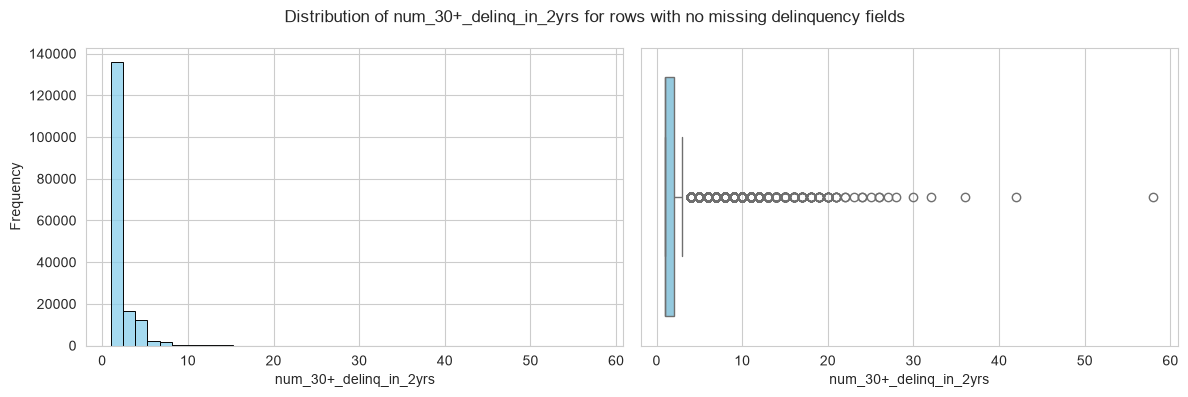

In [40]:
# Visualize the distribution of num_30+_delinq_in_2yrs for rows with no missing delinquency fields
mask = (missing_count == 0) & (X_train[count_col] > 0)
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
sns.histplot(X_train.loc[mask, count_col], bins=40, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('num_30+_delinq_in_2yrs')
plt.ylabel('Frequency')

plt.subplot(1,2,2)
sns.boxplot(x=X_train.loc[mask, count_col], color='skyblue')
plt.xlabel('num_30+_delinq_in_2yrs')

plt.suptitle('Distribution of num_30+_delinq_in_2yrs for rows with no missing delinquency fields')
plt.tight_layout()
plt.show()

### String Features

In [41]:
# Check missing values in string variables
missing_str_var = X_train[STRING_VAR].isnull().sum()
missing_str_var = missing_str_var[missing_str_var > 0].sort_values(ascending=False)
missing_str_var = pd.DataFrame({
    'variable': missing_str_var.index,
    'count': missing_str_var.values,
    'percentage': missing_str_var.values / len(X_train) * 100
})

print("Missing values in string variables:")
missing_str_var

Missing values in string variables:


,variable,count,percentage
0,emp_title,118758,6.938
1,emp_length,104175,6.086


In [42]:
# Check if emp_title is missing when emp_length is missing
mask = X_train["emp_length"].isna()

print(f"Percentage of missing emp_title when emp_length is missing: {X_train.loc[mask, 'emp_title'].isna().mean() * 100:.2f}%")

Percentage of missing emp_title when emp_length is missing: 99.40%


For string variables, just the employment-related variables have missing values. The title has more missing values than the lenght so not all missing lengths can be considered as unemployed users

In [43]:
# Suspicious values that may indicate missing or invalid employment titles
suspicious = {
    # Common missing values
    "", "na", "n/a", "n.a", "n.a.", "n\a", "na.", "#n/a",
    "nan", "null", "nil", "none", "void", "undefined", "unknown", "unk",
    "missing", "blank", "empty", "not available", "not applicable",
    "not specified", "unspecified", "not provided", "not given",
    "no data", "no info", "no information", "none given", "tbd", "tba",
    # Typical errors in Excel
    "#value!", "#ref!", "#div/0!", "#name?", "#null!", "#num!",
    # Common placeholders and test values
    "x", "xx", "xxx", "xxxx", "0", "00", "000", "-1", "999", "9999",
    "test", "dummy", "default", "...",
}
punctuation_pattern = r"^[\W_]+$"


In [44]:
# Check for suspicious values in string variables
for col in missing_str_var['variable']:
    values = X_train[col].dropna()
    mask = values.isin(suspicious) | values.str.match(punctuation_pattern)
    suspicious_counts = values[mask].value_counts()
    if not suspicious_counts.empty:
        print(f"Suspicious values in '{col}':")
        print(suspicious_counts)
        print()

Suspicious values in 'emp_title':
emp_title
na      8
test    3
        2
.       1
Name: count, dtype: int64



In [45]:
mask = X_train['emp_title'].isin(['na', 'test', '', '.'])
X_train.loc[mask]

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
1576209,1600,23.400,62.270,E5,na,10+ years,MORTGAGE,41000.000,Not Verified,other,...,0,NaN,NaN,Cash,36,Dec,2013,7,May,2001
1817051,24000,14.990,570.840,C5,na,10+ years,OWN,110000.000,Verified,debt_consolidation,...,1,NaN,NaN,Cash,60,Oct,2014,5,Nov,1998
1293694,5000,7.990,156.660,A5,.,4 years,RENT,36000.000,Verified,other,...,0,NaN,NaN,Cash,36,Mar,2017,3,Jun,2008
712307,14600,20.750,392.930,E2,na,10+ years,MORTGAGE,72000.000,Not Verified,debt_consolidation,...,1,NaN,NaN,Cash,60,Feb,2016,2,Sep,2003
570838,6000,7.390,186.340,A4,test,4 years,OWN,78400.000,Source Verified,home_improvement,...,3,NaN,NaN,Cash,36,May,2016,1,Mar,2000
1907487,5000,11.670,165.290,B4,na,10+ years,RENT,38000.000,Not Verified,credit_card,...,2,NaN,NaN,Cash,36,Jun,2014,5,Oct,2000
594598,6000,7.390,186.340,A4,,10+ years,OWN,43000.000,Source Verified,debt_consolidation,...,0,NaN,NaN,Cash,36,Apr,2016,0,Oct,1999
124102,32000,10.470,687.330,B2,test,4 years,RENT,65000.000,Verified,credit_card,...,0,NaN,NaN,Cash,60,Sep,2018,9,Nov,2007
196398,11200,15.020,388.370,C3,na,3 years,MORTGAGE,42000.000,Verified,credit_card,...,0,NaN,16.000,Cash,36,Jul,2018,9,Mar,2007
250530,9600,10.410,311.620,B3,,10+ years,OWN,40000.000,Not Verified,credit_card,...,0,NaN,NaN,Cash,36,Jun,2018,0,Oct,1999


They seem to be regular samples, so these values can be considered as null values. 

In [46]:
# Replace suspicious values with NaN for the whole dataset (X) to avoid data leakage
for df in [X_train, X_test]:
    df['emp_title'] = df['emp_title'].mask(df['emp_title'].isin(['na', 'test', '', '.']))
    print(f"Number of missing values in emp_title: {df['emp_title'].isnull().sum()} ({df['emp_title'].isnull().mean() * 100:.3f}%)")


Number of missing values in emp_title: 118772 (6.939%)
Number of missing values in emp_title: 29769 (6.957%)


Missing values for emp_title almost stays the same

In [47]:
# Looking for possible labels for unemployed in the employment title variable
pattern = r"unemployed|jobless|not employed|out of work|laid off|no job|retired|homemaker|stay at home"

# Check for suspicious titles of unemployment
mask = X_train['emp_title'].str.contains(pattern, case=False, na=False)
Unemployed_titles = X_train[mask]['emp_title'].unique().tolist()
Unemployed_titles

['retired/ substitute teacher',
 'radiologist technologist/ army retired',
 'eeo assistant/retired sfc',
 'retired',
 'retired from usdc - courtroom deputy',
 'telemarkreter/ retired',
 'supervisor/retired police officer',
 'retired pension',
 'retired corrections officer / comm. oper',
 'retired from texas southern university',
 'homemakers and companions co,inc',
 'sales/retired',
 'semi-retired teacher',
 'retired -  education specialist',
 'retired teacher/substitute',
 'xmas tree repair part time +retired',
 'retired from verizon new jersey',
 'clerk of circuit court & retired trooper',
 'retired teacher/per diem teacher',
 'gm retired / novatron',
 'substitute, retired teacher',
 'facility cap  pers/retired annuitant',
 'retired kcfd / lowes',
 'homemaker',
 'picking/ retired',
 'dealer / retired from us army',
 'amports & retired city government',
 'homemaker, pca/hha',
 'security guard/retired military',
 'homemaker service of the metro area, inc',
 'security guard pt retired t

Some descriptions related to the word `retired` or homemaker cannot be used to consider the user as some of them continue working as they are, for example, retired form US army but still working. Therefore it is difficult to use this variable to help the model as it is hard to generalize. An AI could be used here to determine based on the description if the user works or not

In [48]:
mask = X_train['emp_length'].isnull() & X_train['emp_title'].notnull()
X_train[mask]['emp_title'].head(20)

769677                                  rn
850670                             teacher
427805               senior vice president
555281                         park ranger
468700                    systems engineer
452423                       sales and man
1151793                               chef
634911                              driver
1069226                            captain
1033512                             ventas
2051764                  teacher{formerly}
849865                      medical biller
1215208                pharmacy technician
565445                real estate investor
2025779     childrens hospital los angeles
1074367    adjunct professor and therapist
881747                             teacher
1042108                           reporter
1029768                        frontloader
845523                  substitute teacher
Name: emp_title, dtype: str

From employment titles of missing values of the employment length it is not possible to know if a missing value reprents unemployment or, for instance, if users that have just started to work

In [49]:
print("Default when emp_title is NaN:", round(y_train[X_train['emp_title'].isna()].mean() * 100, 2), "%")
print("Default when emp_title is not NaN:", round(y_train[~X_train['emp_title'].isna()].mean() * 100, 2), "%")

Default when emp_title is NaN: 15.29 %
Default when emp_title is not NaN: 12.91 %


In [50]:
print("Default when emp_length is NaN:", round(y_train[X_train['emp_length'].isna()].mean() * 100, 2), "%")
print("Default when emp_length is not NaN:", round(y_train[~X_train['emp_length'].isna()].mean() * 100, 2), "%")

Default when emp_length is NaN: 16.27 %
Default when emp_length is not NaN: 12.87 %


There is a difference in both cases about 3 %, which is representative as the default ratio is small in the dataset. NaN are replaced in both cases for 'unknown' for the whole dataset (X)

In [51]:
for df in [X_train, X_test]:
    df[['emp_length', 'emp_title']] = df[['emp_length', 'emp_title']].fillna('unknown')

for name, df in zip(['X_train', 'X_test'], [X_train, X_test]):
    print(f"Number of missing values in emp_length ({name}): {df['emp_length'].isnull().sum()}")
    print(f"Number of missing values in emp_title ({name}): {df['emp_title'].isnull().sum()}")

Number of missing values in emp_length (X_train): 0
Number of missing values in emp_title (X_train): 0
Number of missing values in emp_length (X_test): 0
Number of missing values in emp_title (X_test): 0


In [52]:
# Analysis of default rates based on emplotyment length 
ordered_emp_length = ["unknown", "< 1 year", "1 year",
                       "2 years", "3 years", "4 years", "5 years",
                       "6 years", "7 years", "8 years", "9 years", "10+ years"]

group_emp_length = pd.Series(y_train).groupby(X_train['emp_length']).agg(
    n='size',
    default_rate='mean'
).reindex(ordered_emp_length)
group_emp_length['ic95'] = 1.96 * np.sqrt(group_emp_length["default_rate"] * (1 - group_emp_length["default_rate"]) / group_emp_length["n"])
group_emp_length["ic95_inf"] = group_emp_length["default_rate"] - group_emp_length["ic95"]
group_emp_length["ic95_sup"] = group_emp_length["default_rate"] + group_emp_length["ic95"]

group_emp_length.style.format({"n": "{:,}", "default_rate"
"": "{:.2%}", "ic95": "{:.2%}", "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

,n,default_rate,ic95,ic95_inf,ic95_sup
emp_length,,,,,
unknown,"86,642",13.26%,0.23%,13.04%,13.49%
< 1 year,"107,031",13.12%,0.20%,12.92%,13.33%
1 year,"91,221",13.21%,0.22%,12.99%,13.43%
2 years,"124,252",13.15%,0.19%,12.96%,13.34%
3 years,"110,362",12.85%,0.20%,12.65%,13.05%
4 years,"82,761",12.79%,0.23%,12.56%,13.02%
5 years,"85,339",13.02%,0.23%,12.80%,13.25%
6 years,"61,056",13.12%,0.27%,12.85%,13.38%
7 years,"54,147",13.18%,0.28%,12.90%,13.47%


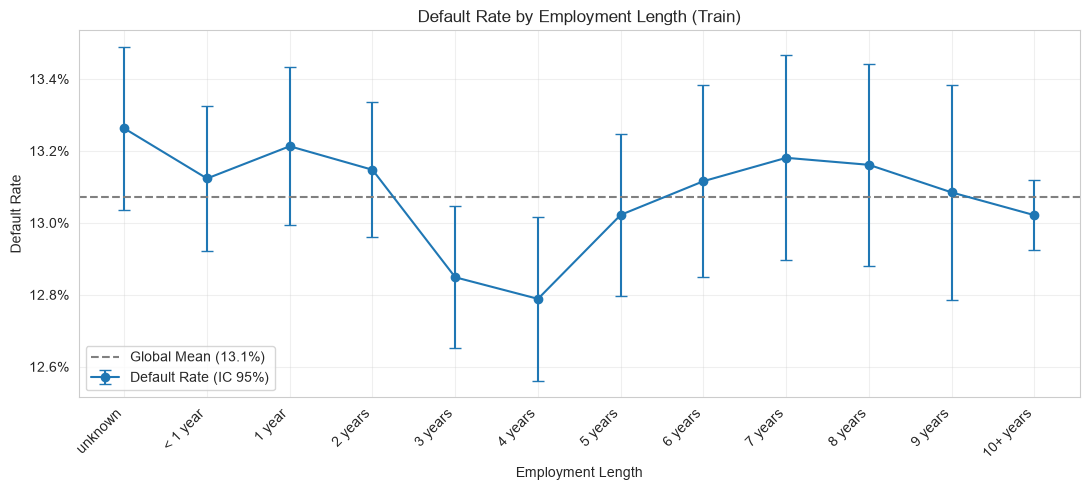

In [53]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.errorbar(range(len(group_emp_length)), group_emp_length["default_rate"], yerr=group_emp_length["ic95"],
            fmt="-o", capsize=4, label="Default Rate (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Global Mean ({y_train.mean():.1%})")

ax.set_xticks(range(len(group_emp_length)))
ax.set_xticklabels(group_emp_length.index, rotation=45, ha="right")
ax.set_xlabel("Employment Length")
ax.set_ylabel("Default Rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Default Rate by Employment Length (Train)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The goal of this analysis is to determine whether different employment length categories have significantly different default rates and identify potential categories to merge.

For each category, we calculate the **default rate** and its **95% confidence interval (CI)**. Based on the Central Limit Theorem, the sampling distribution of the default rate can be approximated by a normal distribution due to the large sample sizes. The confidence intervals quantify the uncertainty around each estimated default rate.

**Key findings:**
- Default rates are very similar across categories, ranging from **12.79% to 13.26%**.
- Most confidence intervals overlap, suggesting that many categories may have similar default risk profiles.
- Categories with larger sample sizes (e.g., `10+ years`) have narrower confidence intervals because their estimates are more precise.
- There is no clear relationship between increasing employment length and decreasing default risk.

**Conclusion:** These results suggest that several employment length categories could be merged to reduce feature complexity without substantially losing predictive information. However, overlapping confidence intervals do not prove that default rates are equal. Any grouping should be validated by comparing model performance before and after merging categories.

New categories are:
- < 3 years
- 3-4 years
- 5 years
- 6 years
- 7-8 years
- 9 years
- +10 years
- unknown

In [54]:
MAP_EMP_LENGTH = {
    "< 1 year": "< 3 years", "1 year": "< 3 years", "2 years": "< 3 years", 
    "3 years": "3-4 years", "4 years": "3-4 years",
    "5 years": "6 years", "6 years": "6 years",
    "7 years": "7-8 years", "8 years": "7-8 years", 
    "9 years": "9 years", "10+ years": "10+ years", "unknown": "unknown",
}

for df in [X_train, X_test]:
    df['emp_length_grouped'] = df['emp_length'].map(MAP_EMP_LENGTH)

print("Number of missing values in emp_length_grouped (X_train):", X_train['emp_length_grouped'].isnull().sum())
X_train['emp_length_grouped'].value_counts()

Number of missing values in emp_length_grouped (X_train): 0


emp_length_grouped
10+ years    571296
< 3 years    403955
3-4 years    242763
6 years      185880
7-8 years    142291
unknown      104175
9 years       61354
Name: count, dtype: int64

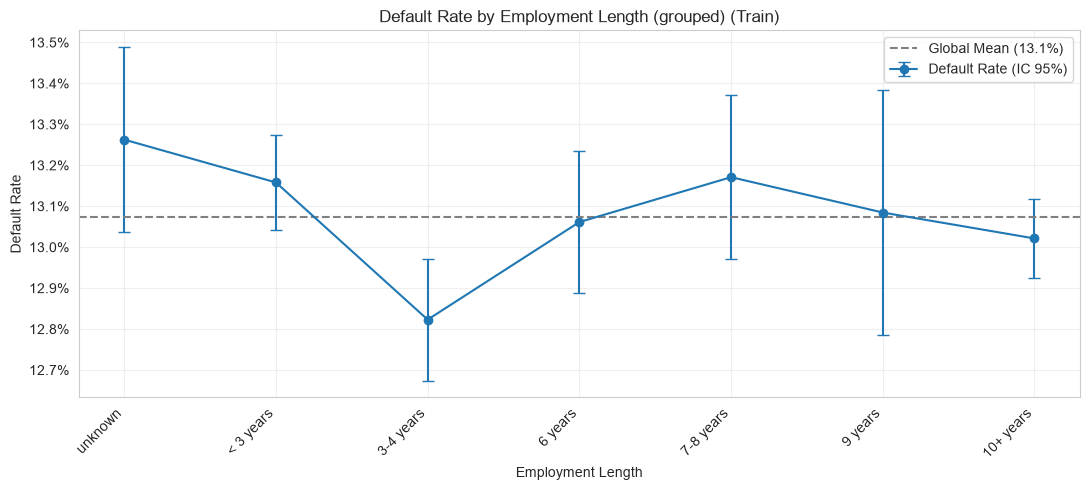

In [55]:
ordered_emp_length_grouped = ["unknown", "< 3 years", "3-4 years", "6 years", "7-8 years", "9 years", "10+ years"]

group_emp_length_grouped = pd.Series(y_train).groupby(X_train['emp_length_grouped']).agg(
    n='size',
    default_rate='mean'
).reindex(ordered_emp_length_grouped)
group_emp_length_grouped['ic95'] = 1.96 * np.sqrt(group_emp_length_grouped["default_rate"] * (1 - group_emp_length_grouped["default_rate"]) / group_emp_length_grouped["n"])
group_emp_length_grouped["ic95_inf"] = group_emp_length_grouped["default_rate"] - group_emp_length_grouped["ic95"]
group_emp_length_grouped["ic95_sup"] = group_emp_length_grouped["default_rate"] + group_emp_length_grouped["ic95"]

fig, ax = plt.subplots(figsize=(11, 5))

ax.errorbar(range(len(group_emp_length_grouped)), group_emp_length_grouped["default_rate"], yerr=group_emp_length_grouped["ic95"],
            fmt="-o", capsize=4, label="Default Rate (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Global Mean ({y_train.mean():.1%})")

ax.set_xticks(range(len(group_emp_length_grouped)))
ax.set_xticklabels(group_emp_length_grouped.index, rotation=45, ha="right")
ax.set_xlabel("Employment Length")
ax.set_ylabel("Default Rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Default Rate by Employment Length (grouped) (Train)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Now let's study deeper `emp_title` as we have seen there is a huge cardinality in this feature where some possible values appear just once

In [56]:
# Export the counts of unique employment titles to a CSV file for further analysis
# X_train['emp_title'].value_counts().to_csv("data/emp_title_counts.csv", index=True)

In [57]:
# Count the number of unique employment titles that appear only once in the training dataset
print(f"Number of unique employment titles that appear only once: {X_train['emp_title'].value_counts()[X_train['emp_title'].value_counts()==1].shape[0]}")
X_train['emp_title'].value_counts()[X_train['emp_title'].value_counts()==1].sample(n=10, random_state=SEED)

Number of unique employment titles that appear only once: 256633


emp_title
city of helena                              1
clubs operation manager                     1
director, integration and outreach solut    1
property and procurement manager            1
uac                                         1
lt/deputy sheriff                           1
licensed  representative                    1
provider network specialist                 1
field process engineer, chemistry           1
school district of collier county           1
Name: count, dtype: int64

The `emp_title` feature contains a large number of unique values, including abbreviations, spelling variants and general job titles. To make this information easier to use in the models, we transform the free text into a set of interpretable features.

The transformer normalizes each title and applies rules based on words and expressions observed in the training data. For example, `RN` and `R.N.` are normalized to `registered nurse`. It also considers context: `hospital accountant` is classified as an accounting role with a healthcare industry context. When the title lacks enough information or matches multiple categories, the output reflects that uncertainty.

The transformer returns:

- **`emp_role_family`**: occupational function, such as healthcare, education or accounting.
- **`emp_industry`**: industry suggested by the title or organization, when available.
- **`emp_record_type`**: whether the text appears to describe a job title, an organization, both, or an employment status.
- **`emp_seniority`**: level suggested by the title, such as senior, manager or director.
- **`emp_employment_status`**: an explicitly stated status, such as self-employed or retired.
- **`emp_management`** and **`emp_ownership`**: indicators of management or ownership terms.
- **`emp_is_placeholder`** and **`emp_is_blank`**: indicators for placeholders such as `unknown` and empty text.
- **`emp_role_ambiguous`** and **`emp_industry_ambiguous`**: indicators for titles that match multiple occupational or industry categories.

The transformer is fitted on the training set and then applied to both training and test data. The resulting features will be compared against a baseline model to assess their predictive value.

In [58]:
from emp_title_features import EmpTitleTransformer
import pandas as pd

# Fit the transformer on the training set
emp_transformer = EmpTitleTransformer()
emp_transformer.fit(X_train[["emp_title"]])

# Generate features for train and test
emp_train = emp_transformer.transform(X_train[["emp_title"]])
emp_test = emp_transformer.transform(X_test[["emp_title"]])

# Add the new features and remove the original text column
X_train_model = pd.concat(
    [X_train.drop(columns="emp_title"), emp_train], axis=1
)
X_test_model = pd.concat(
    [X_test.drop(columns="emp_title"), emp_test], axis=1
)

emp_train.head()

,emp_role_family,emp_industry,emp_record_type,emp_seniority,emp_employment_status,emp_management,emp_ownership,emp_is_placeholder,emp_is_blank,emp_role_ambiguous,emp_industry_ambiguous
1483319,manufacturing_production,unknown,job_title,unspecified,unknown,0,0,0,0,0,0
1401053,unknown,unknown,unknown,unspecified,unknown,0,0,0,0,0,0
1547600,management,unknown,job_title,manager_supervisor,unknown,1,0,0,0,0,0
1895644,unknown,unknown,unknown,unknown,unknown,0,0,1,0,0,0
573351,management,unknown,job_title,manager_supervisor,unknown,1,0,0,0,0,0
